# 44. Large-angle fine/coarse Flow Matching fine-tuning from notebook 43

**Goal:** fine-tune the **already trained FM model** (not the 002.24 regressor) with a fine/coarse prior mixture, unfreezing the Transformer, calibration pooler, MLPBody and velocity head. Analytic SE(3)×ℝ velocity loss only; ODE integration is used for evaluation, not training.

This notebook combines **43**'s FM training/evaluation contracts and **24**'s per-sample fine/coarse regime selection and reversible stochastic small-set learnability check. It deliberately does **not** introduce signed-pair/equivariance losses or change true-calibration augmentation.

- **Source FM:** previous notebook 43 `best.pt`. **Regression control:** 002.24 `best.pt` (not trainable).
- **Fine:** 40% of physical windows, 0–60° truncated Student-t (maintains previous learned regime).
- **Coarse:** 60%, 0–179° **uniform** angular corruption. This is an overlapping mixture, not a hard interval split; the sampling verification shows actual coverage. Change `FINE_ROTATION_MAX_RAD` to 5° to replicate notebook 24's original fine distribution exactly, but that is not the default here because 30–60° improvement is one of our goals.
- **First:** temporary stochastic experiment on a few fixed physical windows with newly drawn corruptions each step, compare on fixed fine and coarse evaluation windows, restore initial weights afterward.
- **Then:** optionally enable the full run. Parameter groups: FM head `1e-4`, Transformer/pooler/MLPBody `1e-5`. Both are trainable. The new experiment uses a **fresh optimizer** and checkpoint directory.
- **Evaluate:** solver ablation on validation; regression vs FM on identically augmented test windows; controlled balanced-angle grid 0–179°; latency/parameters.

**Note:** the code requires the actual KAIST dataset, 002.24 checkpoint, notebook 43 FM checkpoint, and the previously installed `obscalib` FM implementation. A decrease in the stochastic *training* loss is insufficient: inspect fixed fine/coarse losses too. No training outcomes are pre-populated.


## 1. Imports and repository root

In [1]:
from pathlib import Path
from dataclasses import asdict
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the nn-obs-calib repository (with src/obscalib).")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import (AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig)
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import (CalibrationFlowIntegratorConfig, CalibrationFlowLossConfig, CalibrationPoolerConfig, MLPConfig, PooledCalibrationFlowConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig)
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch, TokenBatch
from obscalib.flow_matching.loss import calibration_velocity_loss
from obscalib.geometry.lie import se3_exp, se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__, "CUDA available:", torch.cuda.is_available())

Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126 CUDA available: True


## 2. Reproducible settings and checkpoint 002.24

In [12]:
RUN_NAME = "kaist_pooled_calibration_fm.2_fine_coarse"
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology"
SOURCE_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"
# Set to the actual notebook 43 output directory if different. Unlike notebook 43, we load its entire FM model.
SOURCE_FM_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_fm_head" / "best.pt"
if not SOURCE_FM_CHECKPOINT.is_file():
    candidate = ROOT / "runs" / "kaist_pooled_calibration_002_43_fm_from_00224" / "best.pt"
    if candidate.is_file():
        SOURCE_FM_CHECKPOINT = candidate
RUN_DIR = ROOT / "runs" / RUN_NAME
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"

SEED = 12345
TRAIN_AUG_SEED = 23456
VAL_AUG_SEED = 34567
TEST_AUG_SEED = 45678
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
BATCH_SIZE = 16  # All Transformer blocks now train: increase to 8 only if GPU peak allows it.
NUM_WORKERS = 0

HEAD_LEARNING_RATE = 1e-4
BACKBONE_LEARNING_RATE = 1e-5  # Transformer + pooler + shared MLPBody
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
TRAIN_EPOCHS = 200
LR_REDUCE_STEPS = 5
LR_REDUCE_FACTOR = 0.5
MAX_TRAIN_BATCHES_PER_EPOCH = None
MAX_VAL_BATCHES_PER_EPOCH = None
REGIME_VALIDATION_BATCHES = 4
RUN_STOCHASTIC_CHECK = True
RUN_FULL_TRAINING = True  # IMPORTANT: first inspect the stochastic check; switch this on explicitly.

FM_INTEGRATION_STEPS = 16
FM_INTEGRATION_METHOD = "midpoint"
ABLATION_STEPS = (4, 8, 16, 32)
ABLATION_METHODS = ("midpoint",)
VAL_ABLATION_WINDOWS_PER_SEQUENCE = 8
TEST_WINDOWS_PER_SEQUENCE = 50
TIMING_WINDOWS = 12
TIMING_WARMUP = 3
TIMING_REPEATS = 3

# Per-physical-example regime selection from notebook 24, adapted to large-angle FM.
FINE_PRIOR_PROBABILITY = 0.40
FINE_ROTATION_MAX_RAD = np.deg2rad(60.0)
FINE_ROTATION_SCALE_RAD = np.deg2rad(30.0)
FINE_TIME_OFFSET_MAX_S = 0.500
FINE_TIME_OFFSET_SCALE_S = 0.250
COARSE_ROTATION_MAX_RAD = np.deg2rad(179.0)
COARSE_TIME_OFFSET_MAX_S = 0.500
COARSE_TIME_OFFSET_SCALE_S = 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3
TRUE_ROTATION_MAX_RAD = np.deg2rad(180.0)
TRUE_TIME_OFFSET_MAX_S = 0.030

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
for required in (SOURCE_CHECKPOINT, SOURCE_FM_CHECKPOINT):
    if not required.is_file():
        raise FileNotFoundError(f"Required source checkpoint not found: {required}")
if not (0.0 <= FINE_PRIOR_PROBABILITY <= 1.0):
    raise ValueError("FINE_PRIOR_PROBABILITY must be within [0,1]")
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Source FM checkpoint:", SOURCE_FM_CHECKPOINT)
print("Regression control:", SOURCE_CHECKPOINT)
print(f"Fine: {100*FINE_PRIOR_PROBABILITY:.0f}% <= {np.rad2deg(FINE_ROTATION_MAX_RAD):g}° truncated Student-t")
print(f"Coarse: {100*(1-FINE_PRIOR_PROBABILITY):.0f}% <= {np.rad2deg(COARSE_ROTATION_MAX_RAD):g}° uniform")
print(f"Joint LRs: head={HEAD_LEARNING_RATE:g}, transformer/pooler/MLPBody={BACKBONE_LEARNING_RATE:g}")


Source FM checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm_head/best.pt
Regression control: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt
Fine: 40% <= 60° truncated Student-t
Coarse: 60% <= 179° uniform
Joint LRs: head=0.0001, transformer/pooler/MLPBody=1e-05


## 3. KAIST train / validation / held-out test (from notebook 42)

In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
assert len(set(ALL_SEQUENCE_NAMES)) == len(ALL_SEQUENCE_NAMES)

T_B_L = np.array([[-0.514066, -0.702201, -0.492595, -0.440699], [0.486485, -0.711672, 0.506809, 0.397052], [-0.706447, 0.0208933, 0.707457, 1.90953], [0., 0., 0., 1.]], dtype=float)
T_B_L_right = np.array([[-0.512152, 0.699241, -0.498761, -0.449885], [-0.494811, -0.714859, -0.494104, -0.416713], [-0.702041, -0.0062642, 0.712109, 1.91294], [0., 0., 0., 1.]], dtype=float)
T_I_B = np.array([[1., 0., 0., -0.07], [0., 1., 0., 0.], [0., 0., 1., 1.7], [0., 0., 0., 1.]], dtype=float)
rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Right-LiDAR pose CSV required by 002.24 architecture: {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config, measurement_dtype=DTYPE, source_timestamp_dtype=torch.float64, window_timestamp_dtype=DTYPE)

train_dataset, val_dataset, test_dataset = (make_dataset(names) for names in (TRAIN_NAMES, VAL_NAMES, TEST_NAMES))
for name, ds in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(ds.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"Unexpected calibration keys for {name}: {ds.calibration_keys}")
    print(name, len(ds), "windows")

train_shuffle_generator = torch.Generator().manual_seed(SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

train 2006 windows
validation 418 windows
test 699 windows


## 4. True-calibration augmentation and fine/coarse prior mixture

The **true-calibration** augmentation is unchanged from notebook 43. Following notebook 24, **one fine/coarse regime mask is drawn per physical example**, shared across all calibration keys. Each regime's `CalibrationPriorPerturber` still chooses **one calibration to corrupt per sample**, and translation perturbation stays disabled. The coarse angular magnitude is uniform up to 179°, while the fine component preserves the old truncated Student-t up to 60°.

The resulting mixture is deliberately overlapping. Inspect the empirical counts below, especially 30–60°, 120–150°, and 170–179°.


In [4]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=TRUE_ROTATION_MAX_RAD),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

fine_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=FINE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=FINE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
coarse_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=COARSE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.UNIFORM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=COARSE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=COARSE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
true_calibration_augmenter = AugmentationPipeline(true_calibration_config)
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)


def augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)


def clone_with_current_calibration(window: WindowBatch, new_calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=new_calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)


def sample_fine_coarse_deltas(true_states, generator: torch.Generator, regime: str = "mixed"):
    if regime not in {"mixed", "fine", "coarse"}:
        raise ValueError(f"Unknown calibration regime: {regime}")
    template = next(iter(true_states.values())).transform
    batch_size = len(template)
    if regime == "fine":
        _, xi, tau = fine_prior_perturber(true_states, generator=generator)
        is_fine = torch.ones(batch_size, device=template.device, dtype=torch.bool)
    elif regime == "coarse":
        _, xi, tau = coarse_prior_perturber(true_states, generator=generator)
        is_fine = torch.zeros(batch_size, device=template.device, dtype=torch.bool)
    else:
        is_fine = torch.rand(batch_size, device=template.device, generator=generator) < FINE_PRIOR_PROBABILITY
        _, fine_xi, fine_tau = fine_prior_perturber(true_states, generator=generator)
        _, coarse_xi, coarse_tau = coarse_prior_perturber(true_states, generator=generator)
        xi = {key: torch.where(is_fine[:, None], fine_xi[key], coarse_xi[key]) for key in true_states}
        tau = {key: torch.where(is_fine[:, None], fine_tau[key], coarse_tau[key]) for key in true_states}
    return xi, tau, is_fine


def augment_window(base_window: WindowBatch, generator: torch.Generator, regime: str = "mixed") -> WindowBatch:
    with torch.no_grad():
        physical_truth_window = true_calibration_augmenter(base_window, generator=generator).augmented_window
        true_states = physical_truth_window.current_calibration
        sampled_xi, sampled_tau, _ = sample_fine_coarse_deltas(true_states, generator=generator, regime=regime)
        noisy_states = apply_prior_perturbation(true_states, sampled_xi, sampled_tau)
        return clone_with_current_calibration(physical_truth_window, noisy_states)


def correction_targets(window: WindowBatch):
    if window.targets is None:
        raise ValueError("Augmented window must contain calibration truth targets.")
    targets_xi, targets_tau = {}, {}
    for key, state in window.current_calibration.items():
        target = window.targets[key]
        if target.next_transform is None or target.next_time_offset is None:
            raise ValueError(f"Incomplete target for {key!r}.")
        targets_xi[key] = se3_log(target.next_transform @ torch.linalg.inv(state.transform))
        targets_tau[key] = target.next_time_offset - state.time_offset
    return targets_xi, targets_tau

print("Fine prior config:", fine_prior_config)
print("Coarse prior config:", coarse_prior_config)


Fine prior config: PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=1.0471975511965976, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.5235987755982988, degrees_of_freedom=3), translation=None, time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student_t'>, scale=0.25, degrees_of_freedom=3), one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False)
Coarse prior config: PriorPerturbationConfig(enabled=True, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=3.12413936106985, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=None, time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.TRUNCATED_STUDENT_T: 'truncated_student

### Empirical fine/coarse sampler validation

This test samples priors and checks calibration-key routing, hard angle bounds and actual histogram coverage. It does not update the model.


In [5]:
# Notebook-24 style empirical prior validation. This tests actual output, not just declared maxima.
@torch.no_grad()
def verify_fine_coarse_sampler():
    rng = augmentation_generator(SEED + 711)
    base = window_batch_to(next(iter(train_loader)), DEVICE, dtype=DTYPE)
    truth = true_calibration_augmenter(base, generator=rng).augmented_window.current_calibration
    # Draw repeatedly from the small valid CalibrationState batch; no synthetic state construction.
    angles_list, clock_list, fine_list = [], [], []
    for _ in range(32):
        xi, tau, mask = sample_fine_coarse_deltas(truth, generator=rng)
        angles_list.append(torch.stack([torch.rad2deg(torch.linalg.vector_norm(xi[key][..., :3], dim=-1)) for key in truth], dim=-1).amax(dim=-1))
        clock_list.append(torch.stack([tau[key].abs().reshape(-1) for key in truth], dim=-1).amax(dim=-1))
        fine_list.append(mask)
        assert max(xi[key][..., 3:].abs().max().item() for key in truth) < 1e-6
    max_angle_per_window = torch.cat(angles_list)
    max_clock_per_window = torch.cat(clock_list)
    is_fine = torch.cat(fine_list)
    assert (max_angle_per_window[is_fine] <= np.rad2deg(FINE_ROTATION_MAX_RAD) + 0.1).all()
    assert (max_angle_per_window[~is_fine] <= np.rad2deg(COARSE_ROTATION_MAX_RAD) + 0.1).all()
    assert (max_clock_per_window <= COARSE_TIME_OFFSET_MAX_S + 1e-6).all()
    fractions = pd.cut(max_angle_per_window.cpu().numpy(), bins=[-0.01, 5, 15, 30, 60, 90, 120, 150, 170, 179.1], include_lowest=True).value_counts().sort_index()
    print("fine fraction:", float(is_fine.float().mean()), "| coarse fraction:", float((~is_fine).float().mean()))
    display(fractions.rename("sampled_windows"))
    if (max_angle_per_window[~is_fine] > 150).sum() == 0:
        print("WARNING: no >150° samples in this small draw; inspect perturbation sampling implementation.")
    print("Fine/coarse sampler geometry check: PASS")

verify_fine_coarse_sampler()


fine fraction: 0.390625 | coarse fraction: 0.609375


(-0.011, 5.0]      32
(5.0, 15.0]        78
(15.0, 30.0]       78
(30.0, 60.0]      112
(60.0, 90.0]       49
(90.0, 120.0]      58
(120.0, 150.0]     57
(150.0, 170.0]     33
(170.0, 179.1]     15
Name: sampled_windows, dtype: int64

Fine/coarse sampler geometry check: PASS


## 5. Restore **FM 43 best.pt**, enable gradient updates in every feature block

The regression 002.24 checkpoint is a **read-only control**. Unlike notebook 43, we do not reinitialize or copy any layer from regression. The FM checkpoint loads **all** its weights, including the trained velocity head. The joint optimizer is created after this load and starts fresh.


In [6]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD, ablation_steps=ABLATION_STEPS),
    loss=CalibrationFlowLossConfig(rotation_scale_rad=np.deg2rad(5.0), translation_scale_m=0.05, time_offset_scale_s=0.05, rotation_weight=2.0, translation_weight=1.0, time_offset_weight=1.0, active_rotation_weight=0.75),
    freeze_backbone_initially=False,
)
regression_model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(SOURCE_CHECKPOINT, model=regression_model, map_location=DEVICE, restore_rng_state=False)
regression_model.requires_grad_(False)
regression_model.eval()

fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(device=DEVICE, dtype=DTYPE)
load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.freeze_feature_extractor(False)
fm_loss_weights = flow_config.loss.to_loss_weights()

def count_parameters(model):
    return sum(param.numel() for param in model.parameters())

def count_trainable(model):
    return sum(param.numel() for param in model.parameters() if param.requires_grad)

assert not fm_model.feature_extractor_frozen
for block in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body, fm_model.head):
    assert all(p.requires_grad for p in block.parameters())
display(pd.DataFrame([
    {"model": "002.24 regression", "parameters": count_parameters(regression_model), "trainable": count_trainable(regression_model)},
    {"model": "44 Flow Matching", "parameters": count_parameters(fm_model), "trainable": count_trainable(fm_model)},
]))
print("Entire FM model trainable, initialized from", SOURCE_FM_CHECKPOINT)


,model,parameters,trainable
0,002.24 regression,2554505,0
1,44 Flow Matching,2555399,2555399


Entire FM model trainable, initialized from /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm_head/best.pt


## 6. Reuse the existing WindowStep preprocessing for FM training

`WindowStep` owns the geometry-processing and tokenization logic. Rather than duplicating those unpublished interfaces or running the regression head, a tiny temporary adapter captures the **actual** `TokenBatch` passed to the model and exits before the updater. The training path then calls `fm_model.forward_flow_matching(tokens, ...)` directly. Any earlier exception from geometry/tokenization is re-raised, not swallowed.

In [7]:
class _TokensCaptured(Exception):
    pass

class _TokenCaptureModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.captured_tokens = None
        self.captured_context = None

    def forward(self, tokens, calibration_context=None, **kwargs):
        self.captured_tokens = tokens
        self.captured_context = calibration_context
        raise _TokensCaptured()

geometry_processor = GeometryProcessor()
calibration_updater = CalibrationUpdater()
tokenizer = Tokenizer(measurement_dim=6, calibration_keys=CALIBRATION_KEYS)
capture_model = _TokenCaptureModel()
capture_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=capture_model, calibration_updater=calibration_updater)

def tokenize_window(window: WindowBatch):
    capture_model.captured_tokens = None
    capture_model.captured_context = None
    try:
        capture_step(window)
    except _TokensCaptured:
        pass
    if capture_model.captured_tokens is None:
        raise RuntimeError("WindowStep did not call model; check the pipeline/tokenizer contract.")
    return capture_model.captured_tokens, capture_model.captured_context

def get_model_output(model: nn.Module, tokens: TokenBatch, calibration_context=None, *, steps=None, method=None):
    if isinstance(model, PooledCalibrationFlowModel):
        return model(tokens, calibration_context, num_steps=steps, method=method)
    return model(tokens, calibration_context)

# One check of the physical augmentation and token routing, before training.
smoke_base = window_batch_to(next(iter(train_loader)), DEVICE, dtype=DTYPE)
smoke_window = augment_window(smoke_base, augmentation_generator(TRAIN_AUG_SEED))
smoke_tokens, smoke_context = tokenize_window(smoke_window)
smoke_xi, smoke_tau = correction_targets(smoke_window)
assert tuple(smoke_tokens.calibration_keys) == tuple(smoke_window.current_calibration)
assert all(smoke_xi[k].shape == (len(smoke_tokens.x), 6) and smoke_tau[k].shape == (len(smoke_tokens.x), 1) for k in smoke_tokens.calibration_keys)
with torch.no_grad():
    smoke_output = fm_model.forward_flow_matching(smoke_tokens, smoke_xi, smoke_tau, calibration_context=smoke_context)
assert smoke_output.predicted_velocity.shape == (len(smoke_tokens.x), len(smoke_tokens.calibration_keys), 7)
assert torch.allclose(smoke_output.flow_batch.target_velocity[..., :6], torch.stack([smoke_xi[k] for k in smoke_tokens.calibration_keys], 1))
print("Tokenization and analytic FM supervision smoke test: PASS", tuple(smoke_tokens.x.shape), tuple(smoke_output.predicted_velocity.shape))

Tokenization and analytic FM supervision smoke test: PASS (16, 1098, 8) (16, 3, 7)


## 7. Analytic FM objective (no integration in the training graph)

In [8]:
def flow_supervision(window: WindowBatch, *, generator: torch.Generator, model=None):
    model = fm_model if model is None else model
    # Physical augmentation, tokenization and targets do not need a computation graph.
    with torch.no_grad():
        tokens, context = tokenize_window(window)
        delta_xi, delta_tau = correction_targets(window)
    output = model.forward_flow_matching(tokens, delta_xi, delta_tau, calibration_context=context, generator=generator)
    losses = calibration_velocity_loss(output.predicted_velocity, output.flow_batch.target_velocity, weights=fm_loss_weights)
    return losses, output

with torch.no_grad():
    smoke_loss, smoke_output = flow_supervision(smoke_window, generator=augmentation_generator(TRAIN_AUG_SEED + 99))
assert torch.isfinite(smoke_loss.total)
print(f"Loaded FM analytic loss on a mixed batch: {smoke_loss.total.item():.6f}")


Loaded FM analytic loss on a mixed batch: 82.050644


## 8. Joint optimizer: head and entire pretrained feature extractor

Head at `1e-4`; Transformer + pooler + MLPBody at `1e-5`. **No frozen layers**. The same analytic velocity loss is used for both stochastic precheck and full training. Training is substantially more VRAM-intensive than notebook 43 because the Transformer now needs activation graphs.


In [9]:
head_params = list(fm_model.head.parameters())
feature_params = [p for component in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in component.parameters()]
assert len({id(p) for p in head_params + feature_params}) == len(head_params + feature_params)
optimizer = torch.optim.AdamW([
    {"params": head_params, "lr": HEAD_LEARNING_RATE, "name": "velocity_head"},
    {"params": feature_params, "lr": BACKBONE_LEARNING_RATE, "name": "transformer_pooler_mlp"},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCE_FACTOR, patience=LR_REDUCE_STEPS)


def run_fm_epoch(loader, *, training: bool, seed: int, max_batches=None, regime: str = "mixed"):
    fm_model.train(training)
    aug_generator = augmentation_generator(seed)
    losses_by_component = defaultdict(float)
    examples = 0
    start = time.perf_counter()
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for batch_index, original_batch in enumerate(loader):
            if max_batches is not None and batch_index >= max_batches:
                break
            with torch.no_grad():
                base = window_batch_to(original_batch, DEVICE, dtype=DTYPE)
                augmented = augment_window(base, aug_generator, regime=regime)
            if training:
                optimizer.zero_grad(set_to_none=True)
            losses, _ = flow_supervision(augmented, generator=aug_generator)
            if training:
                losses.total.backward()
                torch.nn.utils.clip_grad_norm_(fm_model.parameters(), GRADIENT_CLIP_NORM)
                optimizer.step()
            batch_size = len(next(iter(augmented.current_calibration.values())).transform)
            values = losses.detached_metrics()
            for key, value in values.items():
                losses_by_component[key] += value if key == "fm_active_rotation_count" else value * batch_size
            examples += batch_size
    if not examples:
        raise RuntimeError("No calibration examples were processed.")
    summary = {key: value if key == "fm_active_rotation_count" else value / examples for key, value in losses_by_component.items()}
    summary.update(num_windows=examples, epoch_seconds=time.perf_counter() - start)
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return summary

# Full-backbone gradient test (not just velocity head).
fm_model.train()
optimizer.zero_grad(set_to_none=True)
loss, _ = flow_supervision(smoke_window, generator=augmentation_generator(TRAIN_AUG_SEED + 99))
loss.total.backward()
for name in ("transformer_encoder", "pooler", "mlp_body", "head"):
    gradients = [p.grad for p in getattr(fm_model, name).parameters() if p.grad is not None]
    assert gradients and all(torch.isfinite(g).all() for g in gradients), f"Missing / nonfinite gradient in {name}"
    print(f"Gradients {name}: norm={sum(g.square().sum().item() for g in gradients)**0.5:.3e}")
optimizer.zero_grad(set_to_none=True)
print("Joint analytic FM gradient smoke: PASS")


Gradients transformer_encoder: norm=3.881e+02
Gradients pooler: norm=6.842e+01
Gradients mlp_body: norm=2.282e+02
Gradients head: norm=3.088e+02
Joint analytic FM gradient smoke: PASS


## 8a. Stochastic **fine/coarse learnability gate** (notebook 24 style)

A handful of fixed physical KAIST windows are repeatedly re-augmented with **fresh true calibration, fine/coarse prior and FM path time**. Evaluation holds two distinct *fine* and *coarse* sets of augmented windows fixed and uses fixed path-time random seeds.

We first measure loss, run short joint training **only for this check**, then restore FM model weights and RNG and delete the diagnostic optimizer. The later full run therefore starts from exactly the original notebook 43 FM checkpoint, not from the smoke-test weights. Review both the mixed loss and the coarse fixed-evaluation loss. `RUN_FULL_TRAINING=False` initially.


STOCHASTIC CHECK: fixed evaluation before {'fine': 0.14781875908374786, 'coarse': 91.02371215820312}
Step   1/400 stochastic_train=19.9841 | fine_fixed=0.1461 | coarse_fixed=89.7962
Step  25/400 stochastic_train=83.9217 | fine_fixed=0.2394 | coarse_fixed=86.0412
Step  50/400 stochastic_train=5.7120 | fine_fixed=0.2894 | coarse_fixed=84.3154
Step  75/400 stochastic_train=59.9328 | fine_fixed=0.2177 | coarse_fixed=80.8562
Step 100/400 stochastic_train=6.6878 | fine_fixed=0.2068 | coarse_fixed=80.7609
Step 125/400 stochastic_train=13.1075 | fine_fixed=0.2609 | coarse_fixed=76.8510
Step 150/400 stochastic_train=2.8019 | fine_fixed=0.2811 | coarse_fixed=76.9660
Step 175/400 stochastic_train=34.3060 | fine_fixed=0.2443 | coarse_fixed=76.1601
Step 200/400 stochastic_train=23.6459 | fine_fixed=0.2671 | coarse_fixed=73.5523
Step 225/400 stochastic_train=6.3087 | fine_fixed=0.2682 | coarse_fixed=71.4231
Step 250/400 stochastic_train=73.6035 | fine_fixed=0.2346 | coarse_fixed=70.6892
Step 275/400

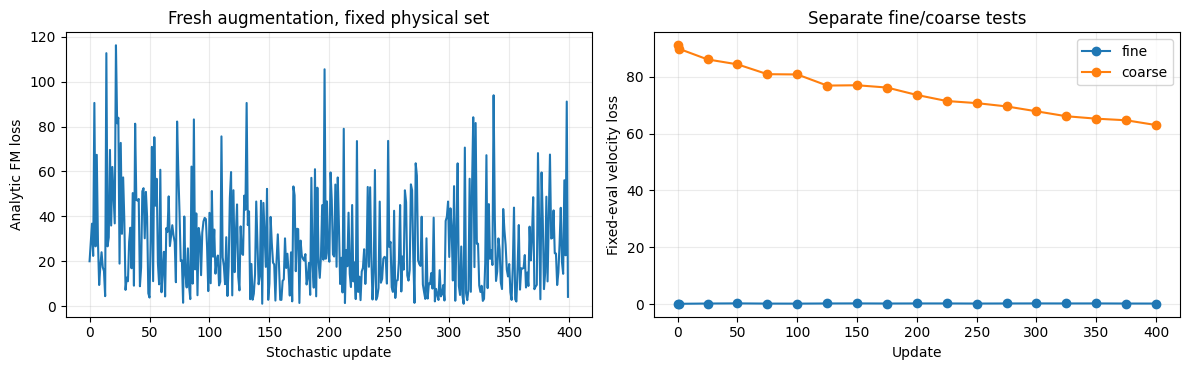

FM model restored after diagnostic; full optimizer has NOT been stepped.


In [28]:
STOCHASTIC_WINDOWS = min(BATCH_SIZE, 16)
STOCHASTIC_STEPS = 400
STOCHASTIC_PRINT_EVERY = 25
STOCHASTIC_SEED = TRAIN_AUG_SEED + 200000
STOCHASTIC_EVAL_SEED = VAL_AUG_SEED + 300000
STOCHASTIC_CHECK_PASSED = None

if RUN_STOCHASTIC_CHECK:
    from copy import deepcopy
    physical_indices = np.unique(np.linspace(0, len(train_dataset) - 1, STOCHASTIC_WINDOWS).astype(int))
    small_base = window_batch_to(collate_windows([train_dataset[int(i)] for i in physical_indices]), DEVICE, dtype=DTYPE)
    with torch.no_grad():
        fixed_eval = {
            regime: augment_window(small_base, augmentation_generator(STOCHASTIC_EVAL_SEED + index), regime=regime)
            for index, regime in enumerate(("fine", "coarse"))
        }

    original_weights = {k: v.detach().cpu().clone() for k, v in fm_model.state_dict().items()}
    rng_cpu = torch.random.get_rng_state().clone()
    rng_cuda = torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None
    rng_np = np.random.get_state()
    rng_python = random.getstate()
    original_mode = fm_model.training
    diagnostic_optimizer = torch.optim.AdamW([
        {"params": list(fm_model.head.parameters()), "lr": HEAD_LEARNING_RATE},
        {"params": [p for block in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in block.parameters()], "lr": BACKBONE_LEARNING_RATE},
    ], weight_decay=WEIGHT_DECAY)
    diagnostic_generator = augmentation_generator(STOCHASTIC_SEED)
    check_steps, check_train_losses = [], []
    check_eval_losses = {"fine": [], "coarse": []}

    @torch.no_grad()
    def evaluate_fixed_stochastic():
        fm_model.eval()
        result = {}
        for idx, regime in enumerate(("fine", "coarse")):
            fixed_gen = augmentation_generator(STOCHASTIC_EVAL_SEED + 1000 + idx)
            losses, _ = flow_supervision(fixed_eval[regime], generator=fixed_gen)
            result[regime] = float(losses.total.item())
        return result

    try:
        initial_losses = evaluate_fixed_stochastic()
        print("STOCHASTIC CHECK: fixed evaluation before", initial_losses)
        for step in range(1, STOCHASTIC_STEPS + 1):
            fm_model.train()
            # Fresh physical augmentation and prior regime each step, but SAME physical windows.
            with torch.no_grad():
                augmented = augment_window(small_base, diagnostic_generator, regime="mixed")
            diagnostic_optimizer.zero_grad(set_to_none=True)
            losses, _ = flow_supervision(augmented, generator=diagnostic_generator)
            losses.total.backward()
            torch.nn.utils.clip_grad_norm_(fm_model.parameters(), GRADIENT_CLIP_NORM)
            diagnostic_optimizer.step()
            check_train_losses.append(float(losses.total.item()))
            if step == 1 or step % STOCHASTIC_PRINT_EVERY == 0 or step == STOCHASTIC_STEPS:
                fixed_losses = evaluate_fixed_stochastic()
                check_steps.append(step)
                for regime in ("fine", "coarse"):
                    check_eval_losses[regime].append(fixed_losses[regime])
                print(f"Step {step:3d}/{STOCHASTIC_STEPS} stochastic_train={losses.total.item():.4f} | fine_fixed={fixed_losses['fine']:.4f} | coarse_fixed={fixed_losses['coarse']:.4f}")
        final_losses = {regime: values[-1] for regime, values in check_eval_losses.items()}
        STOCHASTIC_CHECK_PASSED = all(np.isfinite(v) for v in final_losses.values()) and np.mean(list(final_losses.values())) < np.mean(list(initial_losses.values()))
        print("STOCHASTIC CHECK", "PASS" if STOCHASTIC_CHECK_PASSED else "INCONCLUSIVE/FAIL", "| fixed losses:", initial_losses, "->", final_losses)
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
        axes[0].plot(check_train_losses); axes[0].set(xlabel="Stochastic update", ylabel="Analytic FM loss", title="Fresh augmentation, fixed physical set")
        for regime in ("fine", "coarse"):
            axes[1].plot([0] + check_steps, [initial_losses[regime]] + check_eval_losses[regime], marker="o", label=regime)
        axes[1].set(xlabel="Update", ylabel="Fixed-eval velocity loss", title="Separate fine/coarse tests"); axes[1].legend()
        for ax in axes: ax.grid(alpha=.25)
        fig.tight_layout(); plt.show()
    finally:
        # Reset ALL model state (including any buffers), RNG and optimizer side effects.
        fm_model.load_state_dict(original_weights, strict=True)
        fm_model.train(original_mode)
        fm_model.zero_grad(set_to_none=True)
        torch.random.set_rng_state(rng_cpu)
        if rng_cuda is not None: torch.cuda.set_rng_state_all(rng_cuda)
        np.random.set_state(rng_np)
        random.setstate(rng_python)
        del diagnostic_optimizer, original_weights
        gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    print("FM model restored after diagnostic; full optimizer has NOT been stepped.")
else:
    print("Stochastic check disabled; enable RUN_STOCHASTIC_CHECK to verify mixed-distribution learning.")


## 9. New-run checkpointing and fine/coarse training

A new `best.pt`/`last.pt` pair is saved under the notebook 44 run name. Do **not** restore the 43 optimizer when changing both the distribution and trainable parameter groups. Full training is **opt-in** so the stochastic check can be inspected first. If `RUN_FULL_TRAINING=False`, evaluation compares the **unmodified FM 43 starting checkpoint** with 002.24.


In [11]:
experiment_metadata = {
    "run_name": RUN_NAME, "source_regression_checkpoint": str(SOURCE_CHECKPOINT), "source_fm_checkpoint": str(SOURCE_FM_CHECKPOINT),
    "architecture": "PooledCalibrationFlowModel", "backbone_config": model_config, "flow_config": flow_config,
    "true_calibration_config": true_calibration_config, "fine_prior_config": fine_prior_config, "coarse_prior_config": coarse_prior_config,
    "fine_probability": FINE_PRIOR_PROBABILITY, "training_loss": "analytic_conditional_lie_velocity_mse_only",
    "trainable_blocks": ("head", "mlp_body", "pooler", "transformer_encoder"),
    "data_splits": {"train": tuple(TRAIN_NAMES), "validation": tuple(VAL_NAMES), "test": tuple(TEST_NAMES)},
}
history = []
best_validation_loss = float("inf")
global_step = 0
start_epoch = 0

RESUME_44_FROM_LAST = True  # Set True only for this run, with matching optimizer groups.
if RESUME_44_FROM_LAST:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(LAST_CHECKPOINT_PATH)
    load_training_checkpoint(LAST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, map_location=DEVICE, restore_rng_state=True)
    # The checkpoint is trusted code/data from this repository; extra_state may contain dataclass objects.
    resume_raw = torch.load(LAST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    start_epoch = int(resume_raw["epoch"])
    global_step = int(resume_raw["global_step"])
    best_validation_loss = float(resume_raw["extra_state"]["best_validation_loss"])
    history_file = RUN_DIR / "fm_learning_history.csv"
    if history_file.is_file():
        history = pd.read_csv(history_file).to_dict("records")
        history = [row for row in history if int(row["epoch"]) <= start_epoch]
    if len(optimizer.param_groups) != 2 or fm_model.feature_extractor_frozen:
        raise RuntimeError("Notebook 44 resume requires the same two trainable parameter groups.")
    print(f"Resumed notebook 44 at completed epoch {start_epoch}, LR groups {[g['lr'] for g in optimizer.param_groups]}")



Resumed notebook 44 at completed epoch 40, LR groups [0.0001, 1e-05]


In [13]:
import time

time.sleep(25 * 60)  # Wait for 25 minutes

In [14]:

if DEVICE.type == "cuda": torch.cuda.empty_cache()
if RUN_FULL_TRAINING:
    for epoch in range(start_epoch, TRAIN_EPOCHS):
        train_metrics = run_fm_epoch(train_loader, training=True, seed=TRAIN_AUG_SEED + epoch, max_batches=MAX_TRAIN_BATCHES_PER_EPOCH)
        validation_metrics = run_fm_epoch(val_loader, training=False, seed=VAL_AUG_SEED, max_batches=MAX_VAL_BATCHES_PER_EPOCH)
        fine_metrics = run_fm_epoch(val_loader, training=False, seed=VAL_AUG_SEED + 10, max_batches=REGIME_VALIDATION_BATCHES, regime="fine")
        coarse_metrics = run_fm_epoch(val_loader, training=False, seed=VAL_AUG_SEED + 20, max_batches=REGIME_VALIDATION_BATCHES, regime="coarse")
        global_step += math.ceil(train_metrics["num_windows"] / BATCH_SIZE)
        val_loss = validation_metrics["loss_fm_total"]
        scheduler.step(val_loss)
        history.append({"epoch": epoch + 1, "phase": "joint-fine-coarse", "head_lr": optimizer.param_groups[0]["lr"], "backbone_lr": optimizer.param_groups[1]["lr"], "val_fine/loss_fm_total": fine_metrics["loss_fm_total"], "val_coarse/loss_fm_total": coarse_metrics["loss_fm_total"], **{f"train/{k}": v for k, v in train_metrics.items()}, **{f"val/{k}": v for k, v in validation_metrics.items()}})
        if val_loss < best_validation_loss:
            best_validation_loss = val_loss
            save_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, epoch=epoch + 1, global_step=global_step, metrics=validation_metrics, extra_state={"best_validation_loss": best_validation_loss, "experiment": experiment_metadata})
            suffix = " [BEST]"
        else:
            suffix = ""
        save_training_checkpoint(LAST_CHECKPOINT_PATH, model=fm_model, optimizer=optimizer, scheduler=scheduler, epoch=epoch + 1, global_step=global_step, metrics=validation_metrics, extra_state={"best_validation_loss": best_validation_loss, "experiment": experiment_metadata})
        pd.DataFrame(history).to_csv(RUN_DIR / "fm_learning_history.csv", index=False)
        print(f"Epoch {epoch+1:3d}/{TRAIN_EPOCHS} | train velocity={train_metrics['loss_fm_total']:.4f} val={val_loss:.4f} fine={fine_metrics['loss_fm_total']:.4f} coarse={coarse_metrics['loss_fm_total']:.4f} | head LR={optimizer.param_groups[0]['lr']:.2e} backbone LR={optimizer.param_groups[1]['lr']:.2e} | {suffix}", flush=True)
    if not BEST_CHECKPOINT_PATH.is_file():
        raise RuntimeError("Training produced no best checkpoint.")
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, map_location=DEVICE, restore_rng_state=False)
    print("Selected FM44 best:", BEST_CHECKPOINT_PATH, "loss:", best_validation_loss)
else:
    print("RUN_FULL_TRAINING=False: evaluating initial FM43 checkpoint; no new checkpoint written.")
fm_model.eval()
regression_model.eval()

Epoch  41/200 | train velocity=9.6698 val=10.6265 fine=0.7076 coarse=31.5998 | head LR=1.00e-04 backbone LR=1.00e-05 | 
Epoch  42/200 | train velocity=10.6978 val=10.1416 fine=0.6016 coarse=35.1125 | head LR=1.00e-04 backbone LR=1.00e-05 |  [BEST]
Epoch  43/200 | train velocity=7.9945 val=10.3864 fine=0.4564 coarse=32.8393 | head LR=1.00e-04 backbone LR=1.00e-05 | 
Epoch  44/200 | train velocity=10.5112 val=10.7237 fine=0.4948 coarse=32.4438 | head LR=1.00e-04 backbone LR=1.00e-05 | 
Epoch  45/200 | train velocity=12.4214 val=10.4708 fine=0.6115 coarse=32.9408 | head LR=1.00e-04 backbone LR=1.00e-05 | 
Epoch  46/200 | train velocity=12.4651 val=10.3104 fine=0.5250 coarse=33.0076 | head LR=1.00e-04 backbone LR=1.00e-05 | 
Epoch  47/200 | train velocity=11.4881 val=10.4706 fine=0.4467 coarse=29.6408 | head LR=1.00e-04 backbone LR=1.00e-05 | 
Epoch  48/200 | train velocity=9.4329 val=10.0459 fine=0.5665 coarse=33.2977 | head LR=1.00e-04 backbone LR=1.00e-05 |  [BEST]
Epoch  49/200 | train

KeyboardInterrupt: 

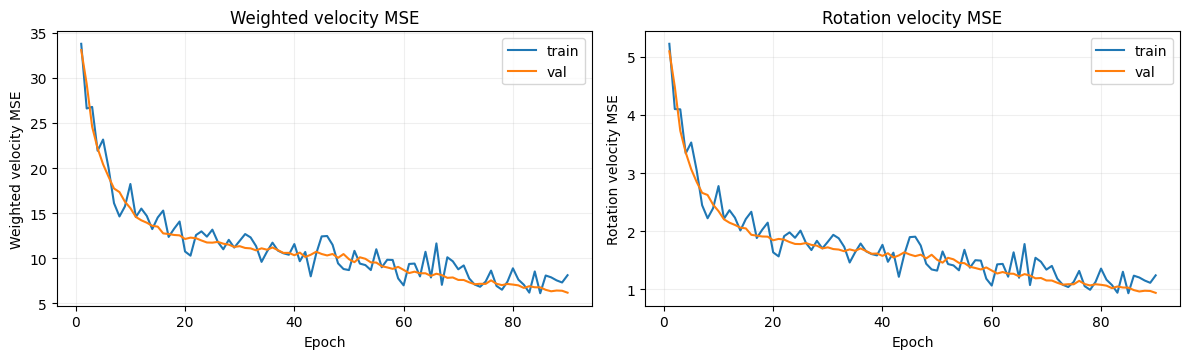

In [15]:
if history:
    hdf = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
    for col, label in (("loss_fm_total", "Weighted velocity MSE"), ("loss_fm_rotation", "Rotation velocity MSE")):
        ax = axes[0] if col == "loss_fm_total" else axes[1]
        for split in ("train", "val"):
            ax.plot(hdf["epoch"], hdf[f"{split}/{col}"], label=split)
        ax.set(xlabel="Epoch", ylabel=label, title=label)
        ax.grid(alpha=0.2); ax.legend()
    fig.tight_layout(); plt.show()

## 10. Build deterministic, paired evaluation cases

All predictions below operate on the **same tokenized window, prior calibration and ground truth**. The validation cases are used exclusively for selecting integration steps. The held-out test cases are used only for the final comparison. Cache prepared cases once to avoid timing/data-order artifacts.

In [16]:
def sampled_indices_by_sequence(dataset, names, per_sequence: int):
    result = []
    for sequence in names:
        indices = np.asarray(dataset.window_indices_for_sequence(sequence), dtype=int)
        if not len(indices):
            continue
        positions = np.unique(np.linspace(0, len(indices) - 1, min(per_sequence, len(indices))).round().astype(int))
        result.extend([(sequence, int(indices[p])) for p in positions])
    if not result:
        raise RuntimeError("No windows found for evaluation.")
    return result

@torch.no_grad()
def prepare_evaluation_cases(dataset, sequences, windows_per_sequence: int, seed: int, regime: str = "mixed"):
    cases = []
    generator = augmentation_generator(seed)
    for sequence, index in sampled_indices_by_sequence(dataset, sequences, windows_per_sequence):
        window = window_batch_to(collate_windows([dataset[index]]), DEVICE, dtype=DTYPE)
        augmented = augment_window(window, generator, regime=regime)
        tokens, context = tokenize_window(augmented)
        xi, tau = correction_targets(augmented)
        cases.append({"sequence": sequence, "index": index, "window": augmented, "tokens": tokens, "context": context, "target_xi": xi, "target_tau": tau})
    return cases

validation_cases = prepare_evaluation_cases(val_dataset, VAL_NAMES, VAL_ABLATION_WINDOWS_PER_SEQUENCE, VAL_AUG_SEED + 900)
print("Fixed validation cases for ODE-step ablation:", len(validation_cases))

Fixed validation cases for ODE-step ablation: 16


## 11. Final-pose metrics with geometric residuals

Compute `Exp(delta_pred) @ T_prior` and compare with target `T_true` in the *actual extrinsic state*. Do not equate raw Lie-algebra coordinate MSE with geometric rotation/translation error. For each calibration key, record initial error, residual error and resulting improvement.

In [17]:
@torch.no_grad()
def correction_metrics(case, prediction, key):
    state = case["window"].current_calibration[key]
    truth = case["window"].targets[key]
    current_T = state.transform
    target_T = truth.next_transform
    predicted_T = se3_exp(prediction.delta_xi) @ current_T
    initial_residual = se3_log(target_T @ torch.linalg.inv(current_T))[:, :3]
    final_residual = se3_log(target_T @ torch.linalg.inv(predicted_T))[:, :3]
    initial_rotation_deg = torch.rad2deg(torch.linalg.vector_norm(initial_residual, dim=-1))
    final_rotation_deg = torch.rad2deg(torch.linalg.vector_norm(final_residual, dim=-1))
    initial_translation_cm = 100 * torch.linalg.vector_norm(current_T[:, :3, 3] - target_T[:, :3, 3], dim=-1)
    final_translation_cm = 100 * torch.linalg.vector_norm(predicted_T[:, :3, 3] - target_T[:, :3, 3], dim=-1)
    initial_tau_ms = 1000 * torch.abs(state.time_offset - truth.next_time_offset).reshape(-1)
    final_tau_ms = 1000 * torch.abs(state.time_offset + prediction.delta_tau - truth.next_time_offset).reshape(-1)
    return {"initial_rotation_deg": initial_rotation_deg, "rotation_error_deg": final_rotation_deg,
            "initial_translation_cm": initial_translation_cm, "translation_error_cm": final_translation_cm,
            "initial_tau_ms": initial_tau_ms, "tau_error_ms": final_tau_ms}

@torch.no_grad()
def evaluate_cases(model, cases, model_label, *, steps=None, method=None):
    model.eval()
    rows = []
    for case in cases:
        output = get_model_output(model, case["tokens"], case["context"], steps=steps, method=method)
        for key, pred in output.predictions.items():
            metrics = correction_metrics(case, pred, key)
            for i in range(len(pred.delta_xi)):
                row = {"model": model_label, "sequence": case["sequence"], "index": case["index"], "key": key}
                row["is_active_fault"] = bool(torch.linalg.vector_norm(case["target_xi"][key][i, :3]).item() > 1e-5 or abs(case["target_tau"][key][i, 0].item()) > 1e-6)
                row.update({metric: float(value[i].item()) for metric, value in metrics.items()})
                row["rotation_gain_deg"] = row["initial_rotation_deg"] - row["rotation_error_deg"]
                rows.append(row)
    return pd.DataFrame(rows)

## 12. Select FM integration resolution on validation windows

Select using validation error with **a practical tolerance**: when two solvers differ by at most 0.02° in mean rotation error, prefer fewer velocity-network evaluations. This avoids selecting 32 steps solely for an insignificant 0.001° gain.


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


,method,steps,NFE,rotation_mean_deg,rotation_p90_deg,translation_mean_cm,tau_mean_ms
0,midpoint,4,8,57.907,126.870,124.891,19.634
1,midpoint,8,16,57.261,127.373,124.606,19.422
2,midpoint,16,32,57.036,127.581,124.473,19.360
3,midpoint,32,64,56.970,127.645,124.429,19.345


Selected FM integration: midpoint, 32 steps, 64 velocity-network evaluations


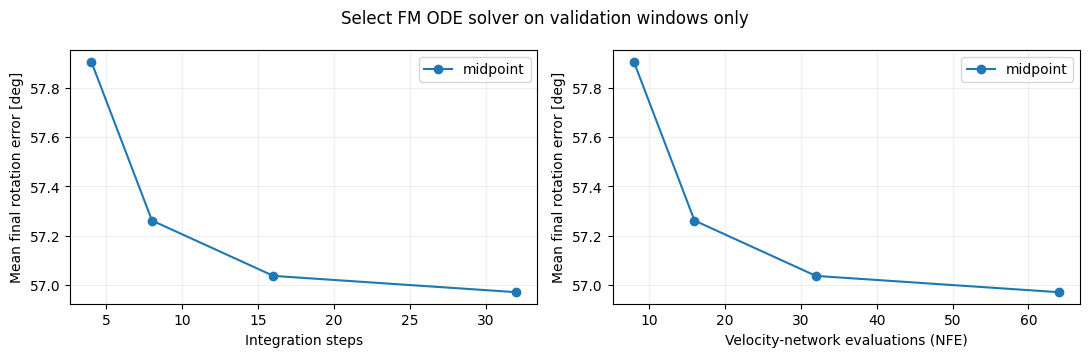

In [18]:
ablation_records = []
for method in ABLATION_METHODS:
    for steps in ABLATION_STEPS:
        values = evaluate_cases(fm_model, validation_cases, "FM", steps=steps, method=method)
        values = values[values.is_active_fault]  # Choose correction fidelity, not healthy-key dominance.
        if values.empty:
            raise RuntimeError("No active calibration faults in validation cases; increase VAL_ABLATION_WINDOWS_PER_SEQUENCE.")
        ablation_records.append({"method": method, "steps": steps, "NFE": steps * (2 if method == "midpoint" else 1),
                                "rotation_mean_deg": values["rotation_error_deg"].mean(),
                                "rotation_p90_deg": values["rotation_error_deg"].quantile(0.9),
                                "translation_mean_cm": values["translation_error_cm"].mean(),
                                "tau_mean_ms": values["tau_error_ms"].mean()})
ablation_df = pd.DataFrame(ablation_records).sort_values(["NFE", "method"])
display(ablation_df.round(3))
ablation_df.to_csv(RUN_DIR / "fm_validation_integration_step_ablation.csv", index=False)

# Choose by rotation error, then fewer NFE. This is a *validation* choice, not a test-set selection.
near_best = ablation_df[ablation_df["rotation_mean_deg"] <= ablation_df["rotation_mean_deg"].min() + 0.02]
selected = near_best.sort_values(["NFE", "rotation_mean_deg"]).iloc[0]
SELECTED_STEPS = int(selected["steps"])
SELECTED_METHOD = str(selected["method"])
print(f"Selected FM integration: {SELECTED_METHOD}, {SELECTED_STEPS} steps, {int(selected['NFE'])} velocity-network evaluations")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for method, table in ablation_df.groupby("method"):
    table = table.sort_values("steps")
    axes[0].plot(table["steps"], table["rotation_mean_deg"], "-o", label=method)
    axes[1].plot(table["NFE"], table["rotation_mean_deg"], "-o", label=method)
for ax, xlabel in zip(axes, ("Integration steps", "Velocity-network evaluations (NFE)")):
    ax.set(xlabel=xlabel, ylabel="Mean final rotation error [deg]")
    ax.grid(alpha=0.2); ax.legend()
fig.suptitle("Select FM ODE solver on validation windows only")
fig.tight_layout(); plt.show()


## 13. Held-out paired evaluation: checkpoint 002.24 versus FM

Report after training, on independent test sequences with identical samples for both models. A table of **absolute residuals** is more informative than comparing FM velocity loss with regression training loss.

In [ ]:
test_cases = prepare_evaluation_cases(test_dataset, TEST_NAMES, TEST_WINDOWS_PER_SEQUENCE, TEST_AUG_SEED + 900)
print("Fixed held-out windows:", len(test_cases))
with torch.inference_mode():
    baseline_test = evaluate_cases(regression_model, test_cases, "002.24 regression")
    fm_test = evaluate_cases(fm_model, test_cases, "FM 44", steps=SELECTED_STEPS, method=SELECTED_METHOD)
test_results = pd.concat((baseline_test, fm_test), ignore_index=True)
test_results.to_csv(RUN_DIR / "fm_vs_00224_paired_test_errors.csv", index=False)

summary_columns = ["initial_rotation_deg", "rotation_error_deg", "rotation_gain_deg", "translation_error_cm", "tau_error_ms"]
summary = test_results.groupby("model")[summary_columns].agg(["mean", "median"])
print("Held-out evaluation. All numbers are measured after executing this notebook.")
display(summary.round(3))
print("ACTIVE FAULTS ONLY (important: prevents healthy calibrations from hiding failure to correct the injected fault):")
display(test_results[test_results.is_active_fault].groupby("model")[["initial_rotation_deg", "rotation_error_deg", "rotation_gain_deg", "translation_error_cm", "tau_error_ms"]].agg(["mean", "median"]).round(3))
print("HEALTHY CALIBRATIONS ONLY (should remain close to zero correction):")
display(test_results[~test_results.is_active_fault].groupby("model")[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]].mean().round(3))
print("Per calibration key (including healthy keys):")
display(test_results.groupby(["model", "key"])[["rotation_error_deg", "translation_error_cm", "tau_error_ms", "rotation_gain_deg"]].mean().round(3))

# Every row must have its counterpart in the other model: no independent test resampling.
paired_keys = ["sequence", "index", "key"]
source_rows = baseline_test.set_index(paired_keys).sort_index()
flow_rows = fm_test.set_index(paired_keys).sort_index()
assert source_rows.index.equals(flow_rows.index)
paired_difference = flow_rows[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]] - source_rows[["rotation_error_deg", "translation_error_cm", "tau_error_ms"]]
print("Paired FM minus regression (negative is better):")
display(paired_difference.agg(["mean", "median"]).round(3)) 


Fixed held-out windows: 100
Held-out evaluation. All numbers are measured after executing this notebook.


initial_rotation_deg        rotation_error_deg         \
                                  mean median               mean median   
model                                                                     
002.24 regression               21.411    0.0             15.257  0.196   
FM 44                           21.411    0.0             15.532  1.202   

                  rotation_gain_deg        translation_error_cm         \
                               mean median                 mean median   
model                                                                    
002.24 regression             6.154 -0.062               27.127  0.453   
FM 44                         5.879 -0.713               32.104  2.988   

                  tau_error_ms         
                          mean median  
model                                  
002.24 regression       15.662  1.099  
FM 44                    9.642  2.518

ACTIVE FAULTS ONLY (important: prevents healthy calibrations from hiding failure to correct the injected fault):


initial_rotation_deg         rotation_error_deg          \
                                  mean  median               mean  median   
model                                                                       
002.24 regression               64.233  44.651             41.614   8.370   
FM 44                           64.233  44.651             44.359  21.129   

                  rotation_gain_deg         translation_error_cm          \
                               mean  median                 mean  median   
model                                                                      
002.24 regression            22.619  21.630               68.533  17.914   
FM 44                        19.874  16.501               90.871  55.560   

                  tau_error_ms          
                          mean  median  
model                                   
002.24 regression       34.411  17.646  
FM 44                   24.350  17.052

HEALTHY CALIBRATIONS ONLY (should remain close to zero correction):


,rotation_error_deg,translation_error_cm,tau_error_ms
model,,,
002.24 regression,2.078,6.424,6.287
FM 44,1.119,2.720,2.288


Per calibration key (including healthy keys):


rotation_error_deg  translation_error_cm  \
model             key                                                     
002.24 regression imu                      16.909                13.921   
                  lidar                    13.928                31.580   
                  lidar_right              14.933                35.879   
FM 44             imu                      19.162                22.001   
                  lidar                    12.334                34.675   
                  lidar_right              15.101                39.635   

                               tau_error_ms  rotation_gain_deg  
model             key                                           
002.24 regression imu                16.989              7.836  
                  lidar              15.350              4.522  
                  lidar_right        14.647              6.105  
FM 44             imu                 8.803              5.583  
                  lidar               9.205              6.116  
                  lidar_right        10.917              5.936

Paired FM minus regression (negative is better):


,rotation_error_deg,translation_error_cm,tau_error_ms
mean,0.276,4.977,-6.020
median,0.822,2.142,0.672


### 13a. Held-out performance on fine and coarse priors separately

Compare FM and regression using the **same** augmented physical windows and prior perturbations, separately for `fine` and `coarse`. The held-out test is only for final reporting, never checkpoint/solver selection.

In [20]:
regime_rows = []
for regime_idx, regime in enumerate(("fine", "coarse")):
    fixed_cases = prepare_evaluation_cases(test_dataset, TEST_NAMES, windows_per_sequence=12, seed=TEST_AUG_SEED + 10000 + regime_idx, regime=regime)
    for label, model in (("002.24 regression", regression_model), ("FM 44", fm_model)):
        results = evaluate_cases(model, fixed_cases, label, steps=SELECTED_STEPS, method=SELECTED_METHOD)
        active = results[results.is_active_fault]
        regime_rows.append({"regime": regime, "model": label, "n_active": len(active),
                            "rotation_mean_deg": active.rotation_error_deg.mean(),
                            "rotation_p90_deg": active.rotation_error_deg.quantile(.9),
                            "translation_mean_cm": active.translation_error_cm.mean(),
                            "tau_mean_ms": active.tau_error_ms.mean()})
regime_summary = pd.DataFrame(regime_rows)
display(regime_summary.round(3))
regime_summary.to_csv(RUN_DIR / "fm_fine_coarse_heldout_comparison.csv", index=False)


,regime,model,n_active,rotation_mean_deg,rotation_p90_deg,translation_mean_cm,tau_mean_ms
0,fine,002.24 regression,24,6.432,12.900,15.198,11.222
1,fine,FM 44,24,12.661,27.779,36.229,13.930
2,coarse,002.24 regression,24,81.723,173.537,174.094,45.577
3,coarse,FM 44,24,78.081,160.236,182.626,30.581


## 14. Performance plots: error distributions, gains, prior-angle bins, time offsets

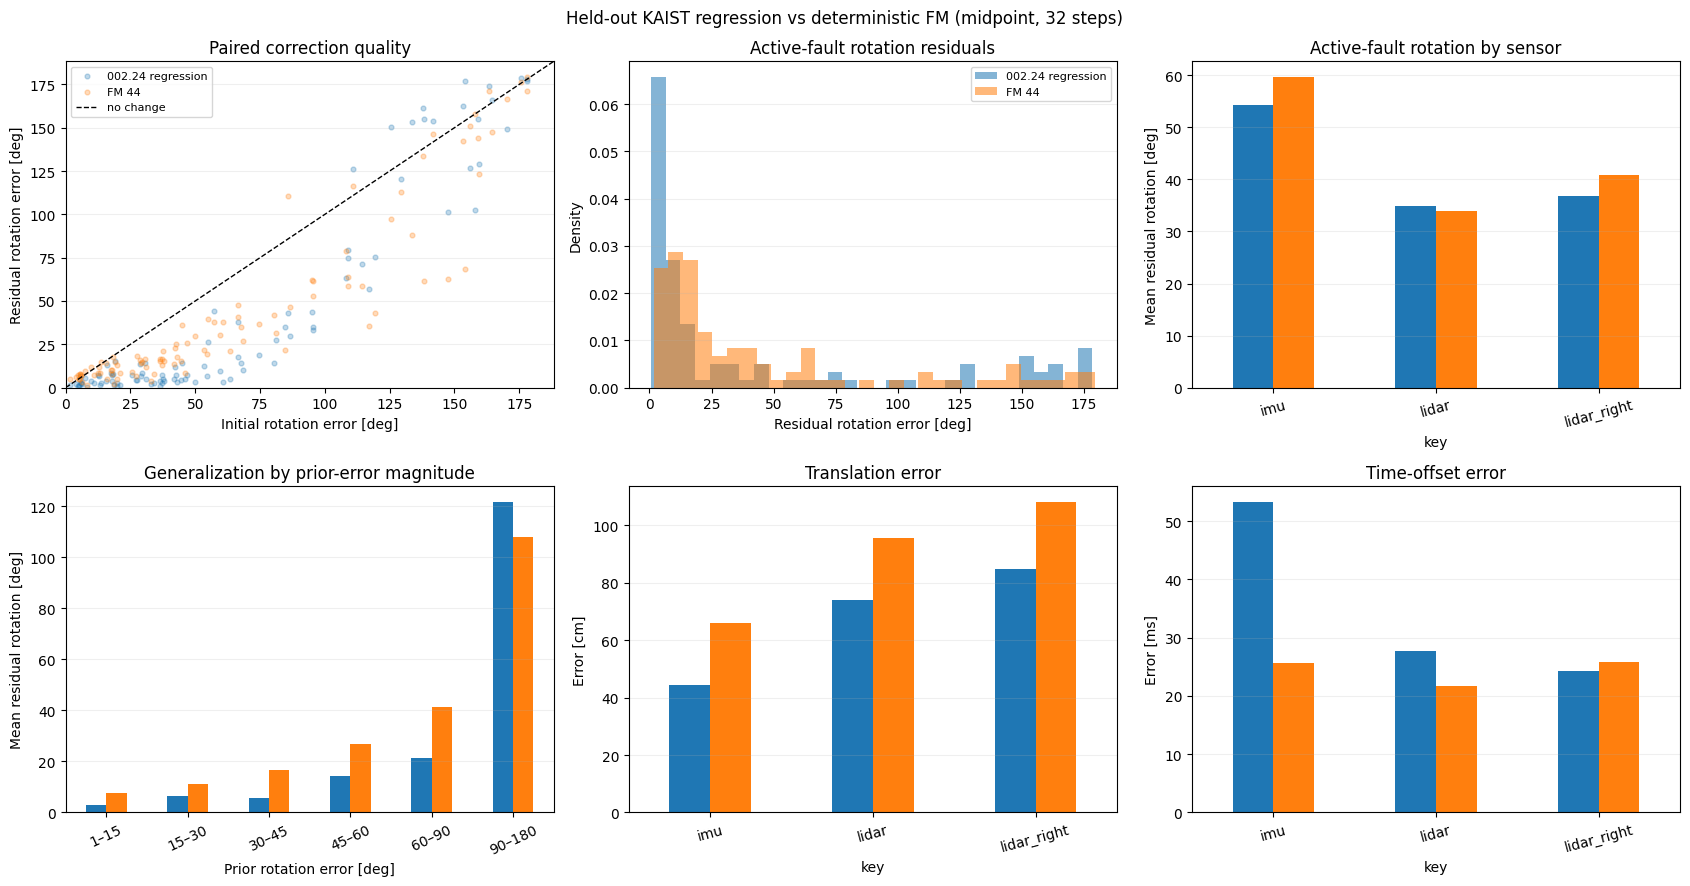

Samples per initial-angle bin:


initial_angle_bin
1–15      18
15–30     17
30–45     16
45–60      8
60–90     12
90–180    29
Name: n, dtype: int64

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
colors = {"002.24 regression": "tab:blue", "FM 44": "tab:orange"}

# 1. Before / after correction for each model.
for model_name, frame in test_results[test_results.is_active_fault].groupby("model"):
    axes[0, 0].scatter(frame["initial_rotation_deg"], frame["rotation_error_deg"], alpha=0.28, s=12, label=model_name, color=colors[model_name])
limit = max(65, float(test_results[["initial_rotation_deg", "rotation_error_deg"]].max().max()) * 1.05)
axes[0, 0].plot([0, limit], [0, limit], "k--", lw=1, label="no change")
axes[0, 0].set(xlabel="Initial rotation error [deg]", ylabel="Residual rotation error [deg]", title="Paired correction quality", xlim=(0, limit), ylim=(0, limit)); axes[0, 0].legend(fontsize=8)

# 2. Rotation error distributions.
for name, data in test_results[test_results.is_active_fault].groupby("model"):
    axes[0, 1].hist(data["rotation_error_deg"], bins=30, alpha=0.55, density=True, color=colors[name], label=name)
axes[0, 1].set(xlabel="Residual rotation error [deg]", ylabel="Density", title="Active-fault rotation residuals"); axes[0, 1].legend(fontsize=8)

# 3. Mean performance by calibration key.
key_means = test_results[test_results.is_active_fault].groupby(["key", "model"])["rotation_error_deg"].mean().unstack("model").reindex(columns=colors.keys())
key_means.plot.bar(ax=axes[0, 2], color=list(colors.values()), rot=15, legend=False)
axes[0, 2].set(ylabel="Mean residual rotation [deg]", title="Active-fault rotation by sensor")

# 4. Error by initial-angle bin. Empty bins remain absent (don't infer missing results).
angle_bins = [-1e-6, 1, 15, 30, 45, 60, 90, 180]
angle_labels = ["0–1", "1–15", "15–30", "30–45", "45–60", "60–90", "90–180"]
plot_df = test_results[test_results.is_active_fault].copy()
plot_df["initial_angle_bin"] = pd.cut(plot_df["initial_rotation_deg"], bins=angle_bins, labels=angle_labels, include_lowest=True)
bins_summary = plot_df.groupby(["initial_angle_bin", "model"], observed=True)["rotation_error_deg"].mean().unstack("model")
bins_summary.plot.bar(ax=axes[1, 0], color=list(colors.values()), rot=25, legend=False)
axes[1, 0].set(xlabel="Prior rotation error [deg]", ylabel="Mean residual rotation [deg]", title="Generalization by prior-error magnitude")

# 5. Translation and 6. clock errors.
for ax, metric, ylabel, title in ((axes[1, 1], "translation_error_cm", "Error [cm]", "Translation error"), (axes[1, 2], "tau_error_ms", "Error [ms]", "Time-offset error")):
    values = test_results[test_results.is_active_fault].groupby(["key", "model"])[metric].mean().unstack("model").reindex(columns=colors.keys())
    values.plot.bar(ax=ax, color=list(colors.values()), rot=15, legend=False)
    ax.set(ylabel=ylabel, title=title)

for ax in axes.flat:
    ax.grid(alpha=0.2, axis="y")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle(f"Held-out KAIST regression vs deterministic FM ({SELECTED_METHOD}, {SELECTED_STEPS} steps)")
fig.tight_layout()
fig.savefig(RUN_DIR / "fm_vs_00224_test_plots.png", dpi=160, bbox_inches="tight")
plt.show()

print("Samples per initial-angle bin:")
display(plot_df[plot_df["model"] == "FM 44"].groupby("initial_angle_bin", observed=True).size().rename("n"))


## 14b. Controlled **balanced-angle evaluation** (portable cell for notebook 43)

Only one calibration key has a rotational prior fault at a time; all others are healthy, time-offset errors are zero. The sampled rotation axis and physically augmented window are identical for regression and FM. No tuning on the held-out test split.


mean   median  count
angle_deg model                                     
0         002.24 regression    0.907    0.679     24
          FM                   3.308    2.391     24
15        002.24 regression    4.118    3.099     24
          FM                   8.872    9.246     24
30        002.24 regression    5.070    4.861     24
          FM                  14.608   14.062     24
45        002.24 regression    5.291    4.184     24
          FM                  15.911   15.195     24
60        002.24 regression    6.686    5.586     24
          FM                  23.153   24.143     24
90        002.24 regression   40.497   33.750     24
          FM                  52.352   48.754     24
120       002.24 regression  114.878  111.295     24
          FM                  89.436   85.929     24
150       002.24 regression  147.817  150.488     24
          FM                 112.243  110.040     24
170       002.24 regression  162.612  168.777     24
          FM                 163.221  169.847     24
179       002.24 regression  162.424  167.175     24
          FM                 163.380  167.092     24

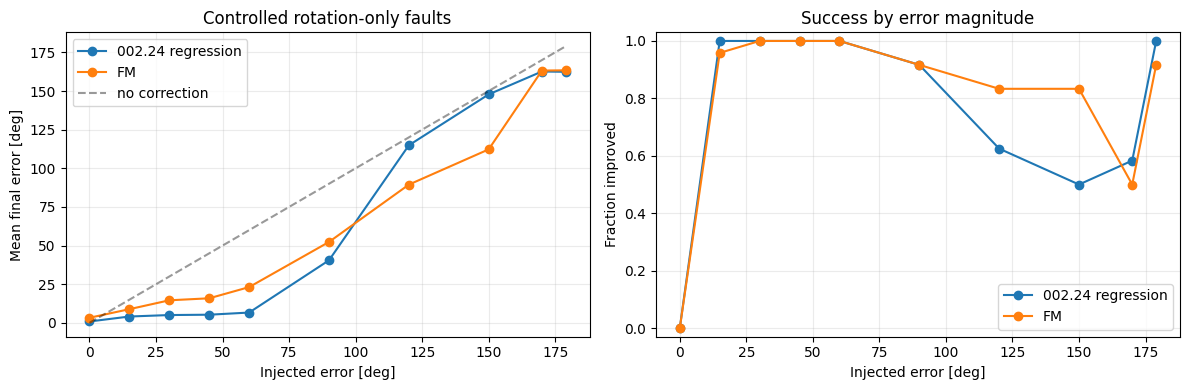

Each point samples 4 physical windows x 2 axes x 3 calibration keys.


In [22]:
# Standalone notebook-43-compatible controlled angular grid. Place after correction_metrics,
# get_model_output, sampled_indices_by_sequence, and SELECTED_STEPS/SELECTED_METHOD exist.
# No random prior magnitudes: EXACT prescribed errors and uniform random axes, one key at a time.
ANGLE_GRID_DEG = (0, 15, 30, 45, 60, 90, 120, 150, 170, 179)
ANGLE_GRID_SPLIT = "validation"  # Switch to "test" for the final untouched held-out grid only.
ANGLE_GRID_WINDOWS_PER_SEQUENCE = 2
ANGLE_GRID_AXES_PER_WINDOW = 2
ANGLE_GRID_SEED = 58721

@torch.inference_mode()
def evaluate_balanced_angle_grid():
    dataset, sequence_names = (val_dataset, VAL_NAMES) if ANGLE_GRID_SPLIT == "validation" else (test_dataset, TEST_NAMES)
    assert ANGLE_GRID_SPLIT in ("validation", "test")
    axes_generator = augmentation_generator(ANGLE_GRID_SEED)
    rows = []
    fm_model.eval()
    regression_model.eval()
    indices = sampled_indices_by_sequence(dataset, sequence_names, ANGLE_GRID_WINDOWS_PER_SEQUENCE)

    for sequence, index in indices:
        base = window_batch_to(collate_windows([dataset[index]]), DEVICE, dtype=DTYPE)
        physical_truth = true_calibration_augmenter(base, generator=axes_generator).augmented_window
        truth_states = physical_truth.current_calibration
        for active_key in CALIBRATION_KEYS:
            for angle_deg in ANGLE_GRID_DEG:
                for axis_index in range(ANGLE_GRID_AXES_PER_WINDOW):
                    axis = torch.randn((1, 3), dtype=DTYPE, device=DEVICE, generator=axes_generator)
                    axis = axis / axis.norm(dim=-1, keepdim=True).clamp_min(1e-12)
                    delta = {key: torch.zeros((1, 6), dtype=DTYPE, device=DEVICE) for key in CALIBRATION_KEYS}
                    delta[active_key][:, :3] = axis * np.deg2rad(angle_deg)
                    tau = {key: torch.zeros((1, 1), dtype=DTYPE, device=DEVICE) for key in CALIBRATION_KEYS}
                    prior = apply_prior_perturbation(truth_states, delta, tau)
                    case_window = clone_with_current_calibration(physical_truth, prior)
                    tokens, context = tokenize_window(case_window)
                    case = {"window": case_window}
                    for label, model in (("002.24 regression", regression_model), ("FM", fm_model)):
                        pred = get_model_output(model, tokens, context, steps=SELECTED_STEPS, method=SELECTED_METHOD).predictions[active_key]
                        metrics = correction_metrics(case, pred, active_key)
                        rows.append({"split": ANGLE_GRID_SPLIT, "sequence": sequence, "index": index, "key": active_key,
                                     "angle_deg": angle_deg, "axis_id": axis_index, "model": label,
                                     **{name: float(values[0].item()) for name, values in metrics.items()}})
    return pd.DataFrame(rows), indices

angle_grid_df, indices = evaluate_balanced_angle_grid()
angle_grid_df.to_csv(RUN_DIR / f"fm_balanced_angle_grid_{ANGLE_GRID_SPLIT}.csv", index=False)
angle_grid_mean = angle_grid_df.groupby(["angle_deg", "model"])["rotation_error_deg"].agg(["mean", "median", "count"])
display(angle_grid_mean.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, data in angle_grid_df.groupby("model"):
    mean = data.groupby("angle_deg")["rotation_error_deg"].mean()
    improved = data.assign(improved=data.rotation_error_deg < data.initial_rotation_deg - 1e-3).groupby("angle_deg")["improved"].mean()
    axes[0].plot(mean.index, mean, "-o", label=name)
    axes[1].plot(improved.index, improved, "-o", label=name)
axes[0].plot(ANGLE_GRID_DEG, ANGLE_GRID_DEG, "k--", alpha=.4, label="no correction")
axes[0].set(xlabel="Injected error [deg]", ylabel="Mean final error [deg]", title="Controlled rotation-only faults")
axes[1].set(xlabel="Injected error [deg]", ylabel="Fraction improved", ylim=(-.03, 1.03), title="Success by error magnitude")
for ax in axes:
    ax.legend(); ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(RUN_DIR / f"fm_balanced_angle_grid_{ANGLE_GRID_SPLIT}.png", dpi=160)
plt.show()
print("Each point samples", len(indices), "physical windows x", ANGLE_GRID_AXES_PER_WINDOW, "axes x", len(CALIBRATION_KEYS), "calibration keys.")


## 15. Parameter count and measured milliseconds per window

**Model-only:** fixed already-tokenized **batch size 1**, `eval()` and `torch.inference_mode()`. **Full window:** `WindowStep` preprocessing, model execution and calibration updater on the *same fixed augmented WindowBatch*. Both use the chosen FM solver. CUDA is synchronized around timing; warmups are excluded. Neither metric includes disk loading or augmentation. Absolute latency depends on hardware and token counts.

In [23]:
def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)

@torch.inference_mode()
def benchmark_callable(fn, *, warmup=TIMING_WARMUP, repeats=TIMING_REPEATS):
    for _ in range(warmup):
        fn()
    synchronize_device()
    readings = []
    for _ in range(repeats):
        synchronize_device()
        start = time.perf_counter()
        fn()
        synchronize_device()
        readings.append(1000 * (time.perf_counter() - start))
    return float(np.median(readings))

regression_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=regression_model, calibration_updater=calibration_updater)
flow_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=fm_model, calibration_updater=calibration_updater)
# Keep the already validated, selected numerical solver for real-world inference.
fm_model.integration_steps = SELECTED_STEPS
fm_model.integration_method = SELECTED_METHOD

regression_model.eval(); fm_model.eval()
bench_cases = test_cases[:min(TIMING_WINDOWS, len(test_cases))]
latency_records = []
for model_label, model, step in (("002.24 regression", regression_model, regression_step), ("FM 44", fm_model, flow_step)):
    times_model, times_pipeline = [], []
    for case in bench_cases:
        times_model.append(benchmark_callable(lambda c=case, m=model: get_model_output(m, c["tokens"], c["context"], steps=SELECTED_STEPS, method=SELECTED_METHOD)))
        times_pipeline.append(benchmark_callable(lambda c=case, s=step: s(c["window"])))
    latency_records.append({"model": model_label, "parameters_total": count_parameters(model), "parameters_trainable_at_evaluation": count_trainable(model), "parameters_prediction_head": count_parameters(model.head),
                            "model_only_median_ms_per_window": float(np.median(times_model)), "model_only_p90_ms_per_window": float(np.quantile(times_model, 0.9)),
                            "full_window_median_ms_per_window": float(np.median(times_pipeline)), "full_window_p90_ms_per_window": float(np.quantile(times_pipeline, 0.9)),
                            "timed_windows": len(times_model), "device": str(DEVICE),
                            "velocity_network_evaluations": 1 if model_label == "002.24 regression" else SELECTED_STEPS * (2 if SELECTED_METHOD == "midpoint" else 1)})
latency_df = pd.DataFrame(latency_records)
latency_df.to_csv(RUN_DIR / "fm_vs_00224_window_timing.csv", index=False)
print(f"Measured on {DEVICE}, {len(bench_cases)} common B=1 windows, median of {TIMING_REPEATS} timed runs after {TIMING_WARMUP} warmups each:")
display(latency_df.round(3))
for row in latency_records:
    print(f"{row['model']}: {row['parameters_total']:,} total params ({row['parameters_prediction_head']:,} in head); "
          f"model-only {row['model_only_median_ms_per_window']:.2f} ms/window; full WindowStep {row['full_window_median_ms_per_window']:.2f} ms/window; "
          f"model evaluations={row['velocity_network_evaluations']}")


Measured on cuda, 12 common B=1 windows, median of 3 timed runs after 3 warmups each:


,model,parameters_total,parameters_trainable_at_evaluation,parameters_prediction_head,model_only_median_ms_per_window,model_only_p90_ms_per_window,full_window_median_ms_per_window,full_window_p90_ms_per_window,timed_windows,device,velocity_network_evaluations
0,002.24 regression,2554505,0,25353,19.035,23.210,36.153,50.429,12,cuda,1
1,FM 44,2555399,2555399,26247,332.954,389.465,375.320,385.305,12,cuda,64


002.24 regression: 2,554,505 total params (25,353 in head); model-only 19.04 ms/window; full WindowStep 36.15 ms/window; model evaluations=1
FM 44: 2,555,399 total params (26,247 in head); model-only 332.95 ms/window; full WindowStep 375.32 ms/window; model evaluations=64


## 16. Summary and reproducibility checklist

These printed numbers are populated **only after training on your data**. The step-count sweep uses validation data; the final error and latency report uses held-out test data. No claim about large-angle improvement beyond the 0–60° training distribution should be made from this first experiment.

In [24]:
print("=" * 84)
print("EXPERIMENT 44: ALL-TRAINABLE FINE/COARSE ANALYTIC FLOW MATCHING")
print("=" * 84)
print("Source regression checkpoint:", SOURCE_CHECKPOINT)
print("Notebook 44 FM best checkpoint (if trained):", BEST_CHECKPOINT_PATH)
print("Training: 40% fine <=60deg truncated Student-t, 60% coarse <=179deg uniform; true calibration rotation <=180deg")
print("FM training: direct velocity MSE; no ODE in loss; starts from FM43 trained weights, all feature blocks fine-tuned")
print(f"Chosen validation solver: {SELECTED_METHOD}, {SELECTED_STEPS} steps")
print("Test windows:", len(test_cases), "| test pose/key pairs:", len(fm_test))
for model_label in ("002.24 regression", "FM 44"):
    scores = test_results[(test_results.model == model_label) & test_results.is_active_fault]
    latency = latency_df[latency_df.model == model_label].iloc[0]
    print(f"{model_label} [ACTIVE FAULTS]: rotation={scores.rotation_error_deg.mean():.3f} deg, translation={scores.translation_error_cm.mean():.3f} cm, tau={scores.tau_error_ms.mean():.3f} ms; "
          f"parameters={int(latency.parameters_total):,}; model-only={latency.model_only_median_ms_per_window:.3f} ms/window; full={latency.full_window_median_ms_per_window:.3f} ms/window")
print("Artifacts saved under:", RUN_DIR)


EXPERIMENT 44: ALL-TRAINABLE FINE/COARSE ANALYTIC FLOW MATCHING
Source regression checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.24_mixed_imu_lidar_topology/best.pt
Notebook 44 FM best checkpoint (if trained): /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.2_fine_coarse/best.pt
Training: 40% fine <=60deg truncated Student-t, 60% coarse <=179deg uniform; true calibration rotation <=180deg
FM training: direct velocity MSE; no ODE in loss; starts from FM43 trained weights, all feature blocks fine-tuned
Chosen validation solver: midpoint, 32 steps
Test windows: 100 | test pose/key pairs: 300
002.24 regression [ACTIVE FAULTS]: rotation=41.614 deg, translation=68.533 cm, tau=34.411 ms; parameters=2,554,505; model-only=19.035 ms/window; full=36.153 ms/window
FM 44 [ACTIVE FAULTS]: rotation=44.359 deg, translation=90.871 cm, tau=24.350 ms; parameters=2,555,399; model-only=332.954 ms/window; full

In [25]:
# Appendix 44.A: rollout settings, matching notebook 32's single-sensor protocol.
from obscalib.calibration.state import CalibrationState
from obscalib.geometry.lie import so3_exp

ROLLOUT_SEQUENCE = "Urban38"                 # Also try Urban39 as a separate run.
ROLLOUT_START = 0
ROLLOUT_NUM_WINDOWS = 20                   # Smoke test: 5; full run: 45-60.
ROLLOUT_SENSORS = tuple(CALIBRATION_KEYS)
ROLLOUT_AXES = (0, 1, 2)                  # X / Y / Z axes.
ROLLOUT_INITIAL_ANGLES_DEG = (0, 15, 45, 90, 130, 170, 179)
ROLLOUT_SIGNS = (1.0,)                    # Add -1.0 for signed-axis robustness.
ROLLOUT_RUN_ROTATION = True
ROLLOUT_RUN_MIXED = True
ROLLOUT_RUN_TAU_ONLY = True
ROLLOUT_MIXED_ANGLES_DEG = (45.0, 120.0)
ROLLOUT_MIXED_TAU_MS = (150.0,)
ROLLOUT_TAU_ONLY_MS = (-150.0, 150.0)
ROLLOUT_FM_STEPS = 16
ROLLOUT_FM_METHOD = "midpoint"

# Follow notebook 32: change only the deliberately faulty sensor, preserve its translation
# and do not update its clock in rotation-only experiments.
ROLLOUT_ROTATION_GAIN = 1.0
ROLLOUT_TAU_GAIN = 1.0
ROLLOUT_MAX_ROTATION_STEP_DEG = None       # Optional safety/damping ablation, e.g. 20.0.
ROLLOUT_MAX_TAU_STEP_MS = None            # Optional safety/damping ablation, e.g. 50.0.
ROLLOUT_UPDATE_TRANSLATION = False       # True: apply full left SE(3) delta including translation.
ROLLOUT_TRANSLATION_GAIN = 1.0
ROLLOUT_MAX_TRANSLATION_STEP_M = None
ROLLOUT_LOAD_BEST_FM44 = True
ROLLOUT_SAVE_RESULTS = True
ROLLOUT_DIR = RUN_DIR / "rollouts" / ROLLOUT_SEQUENCE

if ROLLOUT_LOAD_BEST_FM44:
    if not BEST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f"Train notebook 44 first, or set ROLLOUT_LOAD_BEST_FM44=False: {BEST_CHECKPOINT_PATH}")
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, map_location=DEVICE, restore_rng_state=False)

fm_model.eval()
regression_model.eval()
if ROLLOUT_SAVE_RESULTS:
    ROLLOUT_DIR.mkdir(parents=True, exist_ok=True)

rollout_indices = list(test_dataset.window_indices_for_sequence(ROLLOUT_SEQUENCE))[ROLLOUT_START:ROLLOUT_START + ROLLOUT_NUM_WINDOWS]
if not rollout_indices:
    raise ValueError(f"No rollout windows in {ROLLOUT_SEQUENCE} from index {ROLLOUT_START}")
rollout_windows = [window_batch_to(collate_windows([test_dataset[int(index)]]), DEVICE, dtype=DTYPE) for index in rollout_indices]
ROLLOUT_MODELS = {"Regression 2.24": regression_model, "FM 44": fm_model}
print(f"{ROLLOUT_SEQUENCE}: {len(rollout_windows)} chronological windows, solver={ROLLOUT_FM_METHOD}/{ROLLOUT_FM_STEPS}")
print("Nominal, unaugmented KAIST windows; no ground truth is supplied to the models.")


Urban38: 20 chronological windows, solver=midpoint/16
Nominal, unaugmented KAIST windows; no ground truth is supplied to the models.


In [26]:
# Appendix 44.B: perturb one sensor, carry the prediction to the next window, measure true errors.
def rollout_copy_states(states):
    return {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in states.items()}


def rollout_so3_error_deg(estimated, reference):
    relative = reference @ estimated.transpose(-1, -2)
    skew = torch.stack((relative[..., 2, 1] - relative[..., 1, 2], relative[..., 0, 2] - relative[..., 2, 0], relative[..., 1, 0] - relative[..., 0, 1]), dim=-1)
    sin_angle = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_angle = 0.5 * (relative.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1.0)
    return torch.rad2deg(torch.atan2(sin_angle, cos_angle))


def rollout_clamp_vector(vector, bound):
    if bound is None:
        return vector
    magnitude = torch.linalg.vector_norm(vector, dim=-1, keepdim=True).clamp_min(1e-12)
    return vector * (float(bound) / magnitude).clamp(max=1.0)


def rollout_make_initial(truth, key, *, rotation_vector_deg=(0.0, 0.0, 0.0), tau_ms=0.0):
    states = rollout_copy_states(truth)
    current = states[key]
    rotation_vector = torch.as_tensor(rotation_vector_deg, dtype=current.transform.dtype, device=current.transform.device).reshape(1, 3).expand(current.transform.shape[0], -1)
    transform = current.transform.clone()
    transform[:, :3, :3] = so3_exp(torch.deg2rad(rotation_vector)) @ transform[:, :3, :3]
    states[key] = CalibrationState(transform=transform, time_offset=current.time_offset + float(tau_ms) / 1000.0)
    return states


def rollout_apply_prediction(states, prediction, key, scenario):
    current = states[key]
    predicted_xi = prediction.delta_xi
    apply_rotation = scenario != "tau_only"
    apply_tau = scenario != "rotation_only"
    dr = ROLLOUT_ROTATION_GAIN * predicted_xi[:, :3] if apply_rotation else torch.zeros_like(predicted_xi[:, :3])
    dr = rollout_clamp_vector(dr, None if ROLLOUT_MAX_ROTATION_STEP_DEG is None else np.deg2rad(ROLLOUT_MAX_ROTATION_STEP_DEG))
    dt = ROLLOUT_TRANSLATION_GAIN * predicted_xi[:, 3:] if ROLLOUT_UPDATE_TRANSLATION and apply_rotation else torch.zeros_like(predicted_xi[:, 3:])
    dt = rollout_clamp_vector(dt, ROLLOUT_MAX_TRANSLATION_STEP_M)
    transform = current.transform.clone()
    if ROLLOUT_UPDATE_TRANSLATION and apply_rotation:
        transform = se3_exp(torch.cat((dr, dt), dim=-1)) @ transform
    elif apply_rotation:
        transform[:, :3, :3] = so3_exp(dr) @ transform[:, :3, :3]
    d_tau = ROLLOUT_TAU_GAIN * prediction.delta_tau if apply_tau else torch.zeros_like(current.time_offset)
    d_tau = rollout_clamp_vector(d_tau, None if ROLLOUT_MAX_TAU_STEP_MS is None else ROLLOUT_MAX_TAU_STEP_MS / 1000.0)
    updated = rollout_copy_states(states)
    updated[key] = CalibrationState(transform=transform, time_offset=current.time_offset + d_tau)
    for healthy in states:
        if healthy != key:
            assert torch.equal(updated[healthy].transform, states[healthy].transform)
            assert torch.equal(updated[healthy].time_offset, states[healthy].time_offset)
    return updated, float(torch.rad2deg(torch.linalg.vector_norm(dr, dim=-1)).mean().item()), float((1000.0 * d_tau).mean().item())


def rollout_metrics(states, truth, key):
    estimated, correct = states[key], truth[key]
    return {
        "rotation_error_deg": float(rollout_so3_error_deg(estimated.transform[:, :3, :3], correct.transform[:, :3, :3]).mean().item()),
        "translation_error_cm": float((100.0 * torch.linalg.vector_norm(estimated.transform[:, :3, 3] - correct.transform[:, :3, 3], dim=-1)).mean().item()),
        "tau_error_ms": float((1000.0 * (estimated.time_offset - correct.time_offset).abs()).mean().item()),
        "signed_tau_error_ms": float((1000.0 * (estimated.time_offset - correct.time_offset)).mean().item()),
    }


@torch.inference_mode()
def run_fm44_matched_rollout(sensor, *, scenario="rotation_only", axis="x", initial_rotvec_deg=(0, 0, 0), initial_tau_ms=0.0):
    if scenario not in {"rotation_only", "mixed", "tau_only"} or sensor not in CALIBRATION_KEYS:
        raise ValueError((scenario, sensor))
    if not rollout_windows:
        raise RuntimeError("No rollout windows selected")
    reference = rollout_windows[0].current_calibration
    carries = {name: rollout_make_initial(reference, sensor, rotation_vector_deg=initial_rotvec_deg, tau_ms=initial_tau_ms) for name in ROLLOUT_MODELS}
    rows = []
    initial_angle_deg = float(np.linalg.norm(initial_rotvec_deg))

    for model_name, carry in carries.items():
        rows.append(dict(model=model_name, sensor=sensor, scenario=scenario, axis=axis, initial_angle_deg=initial_angle_deg, initial_tau_ms=float(initial_tau_ms),
                         signed_initial_rotvec_deg=str(tuple(float(v) for v in initial_rotvec_deg)), step=0, window_index=-1, predicted_rotation_step_deg=0.0, predicted_tau_step_ms=0.0,
                         **rollout_metrics(carry, reference, sensor)))

    for step, (index, window) in enumerate(zip(rollout_indices, rollout_windows), start=1):
        for model_name, model in ROLLOUT_MODELS.items():
            current = carries[model_name]
            hypothesis = clone_with_current_calibration(window, current)
            tokens, context = tokenize_window(hypothesis)  # Must recompute with updated calibration!
            predictions = get_model_output(model, tokens, context, steps=ROLLOUT_FM_STEPS, method=ROLLOUT_FM_METHOD).predictions
            updated, predicted_rotation_step_deg, predicted_tau_step_ms = rollout_apply_prediction(current, predictions[sensor], sensor, scenario)
            carries[model_name] = updated
            rows.append(dict(model=model_name, sensor=sensor, scenario=scenario, axis=axis, initial_angle_deg=initial_angle_deg, initial_tau_ms=float(initial_tau_ms),
                             signed_initial_rotvec_deg=str(tuple(float(v) for v in initial_rotvec_deg)), step=step, window_index=int(index),
                             predicted_rotation_step_deg=predicted_rotation_step_deg, predicted_tau_step_ms=predicted_tau_step_ms,
                             **rollout_metrics(updated, window.current_calibration, sensor)))

    return pd.DataFrame.from_records(rows)

# Check the geometric initialization at both small and near-180° errors.
with torch.inference_mode():
    reference = rollout_windows[0].current_calibration
    for key in ROLLOUT_SENSORS:
        for angle_deg in (0.0, 45.0, 179.0):
            initial = rollout_make_initial(reference, key, rotation_vector_deg=(angle_deg, 0.0, 0.0))
            measured = rollout_metrics(initial, reference, key)["rotation_error_deg"]
            assert abs(measured - angle_deg) < 0.03, (key, angle_deg, measured)
print("Single-sensor rollout initialization: PASS")


Single-sensor rollout initialization: PASS


In [27]:
# Appendix 44.C: matched chronological experiments, including zero-error drift and IMU tau.
rollout_experiments = []
if ROLLOUT_RUN_ROTATION:
    for sensor in ROLLOUT_SENSORS:
        for axis_index in ROLLOUT_AXES:
            for angle_deg in ROLLOUT_INITIAL_ANGLES_DEG:
                if angle_deg == 0 and axis_index != ROLLOUT_AXES[0]:
                    continue
                for sign in (ROLLOUT_SIGNS if angle_deg else (1.0,)):
                    vector = np.zeros(3)
                    vector[axis_index] = sign * angle_deg
                    rollout_experiments.append(dict(sensor=sensor, scenario="rotation_only", axis="xyz"[axis_index], initial_rotvec_deg=vector, initial_tau_ms=0.0))

if ROLLOUT_RUN_MIXED:
    mixed_direction = np.asarray((1.0, -0.5, 0.25))
    mixed_direction /= np.linalg.norm(mixed_direction)
    for sensor in ROLLOUT_SENSORS:
        for angle_deg in ROLLOUT_MIXED_ANGLES_DEG:
            for tau_ms in ROLLOUT_MIXED_TAU_MS:
                rollout_experiments.append(dict(sensor=sensor, scenario="mixed", axis="mixed", initial_rotvec_deg=angle_deg * mixed_direction, initial_tau_ms=tau_ms))

if ROLLOUT_RUN_TAU_ONLY:
    for sensor in ROLLOUT_SENSORS:
        for tau_ms in ROLLOUT_TAU_ONLY_MS:
            rollout_experiments.append(dict(sensor=sensor, scenario="tau_only", axis="tau", initial_rotvec_deg=np.zeros(3), initial_tau_ms=tau_ms))

print(f"Running {len(rollout_experiments)} matched scenarios x {len(rollout_windows)} windows x {len(ROLLOUT_MODELS)} models")
rollout_frames = []
for case_index, params in enumerate(rollout_experiments, start=1):
    print(f"{case_index}/{len(rollout_experiments)}: {params['sensor']} {params['scenario']} {np.round(params['initial_rotvec_deg'], 1)} deg, tau={params['initial_tau_ms']:+g} ms", flush=True)
    rollout_frames.append(run_fm44_matched_rollout(**params))

rollout_data = pd.concat(rollout_frames, ignore_index=True)
if ROLLOUT_SAVE_RESULTS:
    rollout_data.to_csv(ROLLOUT_DIR / "fm44_vs_regression_chronological_rollouts.csv", index=False)

# Every model was evaluated on identical initial errors and identical physical windows.
case_columns = ["sensor", "scenario", "axis", "initial_angle_deg", "initial_tau_ms", "signed_initial_rotvec_deg"]
assert rollout_data.groupby(case_columns + ["model"]).size().eq(len(rollout_windows) + 1).all()

rollout_terminal = rollout_data.sort_values("step").groupby(case_columns + ["model"], as_index=False).last()
rollout_terminal["solved_5deg"] = rollout_terminal.rotation_error_deg < 5.0
rollout_terminal["solved_tau_25ms"] = rollout_terminal.tau_error_ms < 25.0
rollout_terminal["improved_rotation"] = rollout_terminal.rotation_error_deg < rollout_terminal.initial_angle_deg - 1e-3

print("Final rotation-only errors, grouped across sensors and axes:")
display(rollout_terminal[rollout_terminal.scenario == "rotation_only"].groupby(["initial_angle_deg", "model"])["rotation_error_deg"].agg(["mean", "median", "max", "count"]).round(2))
print("Final rotation-only convergence rates:")
display(rollout_terminal[rollout_terminal.scenario == "rotation_only"].groupby(["initial_angle_deg", "model"])[["solved_5deg", "improved_rotation"]].mean().round(3))
print("Final tau-only errors by sensor:")
display(rollout_terminal[rollout_terminal.scenario == "tau_only"].groupby(["sensor", "initial_tau_ms", "model"])[["tau_error_ms", "signed_tau_error_ms"]].mean().round(2))

if ROLLOUT_SAVE_RESULTS:
    rollout_terminal.to_csv(ROLLOUT_DIR / "fm44_vs_regression_rollout_terminal.csv", index=False)


Running 69 matched scenarios x 20 windows x 2 models
1/69: imu rotation_only [0. 0. 0.] deg, tau=+0 ms
2/69: imu rotation_only [15.  0.  0.] deg, tau=+0 ms
3/69: imu rotation_only [45.  0.  0.] deg, tau=+0 ms
4/69: imu rotation_only [90.  0.  0.] deg, tau=+0 ms
5/69: imu rotation_only [130.   0.   0.] deg, tau=+0 ms
6/69: imu rotation_only [170.   0.   0.] deg, tau=+0 ms
7/69: imu rotation_only [179.   0.   0.] deg, tau=+0 ms
8/69: imu rotation_only [ 0. 15.  0.] deg, tau=+0 ms
9/69: imu rotation_only [ 0. 45.  0.] deg, tau=+0 ms
10/69: imu rotation_only [ 0. 90.  0.] deg, tau=+0 ms
11/69: imu rotation_only [  0. 130.   0.] deg, tau=+0 ms
12/69: imu rotation_only [  0. 170.   0.] deg, tau=+0 ms
13/69: imu rotation_only [  0. 179.   0.] deg, tau=+0 ms
14/69: imu rotation_only [ 0.  0. 15.] deg, tau=+0 ms
15/69: imu rotation_only [ 0.  0. 45.] deg, tau=+0 ms
16/69: imu rotation_only [ 0.  0. 90.] deg, tau=+0 ms
17/69: imu rotation_only [  0.   0. 130.] deg, tau=+0 ms
18/69: imu rotation_

mean  median     max  count
initial_angle_deg model                                         
0.0               FM 44             11.28   11.01   12.80      3
                  Regression 2.24    2.15    2.39    2.55      3
15.0              FM 44             11.28   11.01   12.80      9
                  Regression 2.24    2.21    2.44    3.02      9
45.0              FM 44             11.28   11.01   12.80      9
                  Regression 2.24    2.31    2.51    3.59      9
90.0              FM 44             47.86   12.80  177.07      9
                  Regression 2.24   26.93    2.55  176.69      9
130.0             FM 44             81.48   12.80  176.49      9
                  Regression 2.24  100.22  176.28  179.82      9
170.0             FM 44             81.47   12.81  176.49      9
                  Regression 2.24  115.49  133.35  179.76      9
179.0             FM 44            117.96  164.48  176.49      9
                  Regression 2.24  113.55  125.73  179.62      9

Final rotation-only convergence rates:


solved_5deg  improved_rotation
initial_angle_deg model                                          
0.0               FM 44                  0.000              0.000
                  Regression 2.24        1.000              0.000
15.0              FM 44                  0.000              1.000
                  Regression 2.24        1.000              1.000
45.0              FM 44                  0.000              1.000
                  Regression 2.24        1.000              1.000
90.0              FM 44                  0.000              0.778
                  Regression 2.24        0.778              0.889
130.0             FM 44                  0.000              0.556
                  Regression 2.24        0.444              0.444
170.0             FM 44                  0.000              0.778
                  Regression 2.24        0.111              0.556
179.0             FM 44                  0.000              1.000
                  Regression 2.24        0.111              0.889

Final tau-only errors by sensor:


tau_error_ms  signed_tau_error_ms
sensor      initial_tau_ms model                                             
imu         -150.0         FM 44                    1.77                -1.77
                           Regression 2.24          0.31                -0.31
             150.0         FM 44                    1.56                -1.56
                           Regression 2.24          0.31                -0.31
lidar       -150.0         FM 44                   37.08                37.08
                           Regression 2.24         17.13                17.13
             150.0         FM 44                   37.08                37.08
                           Regression 2.24         17.13                17.13
lidar_right -150.0         FM 44                    3.47                 3.47
                           Regression 2.24          1.12                -1.12
             150.0         FM 44                    3.47                 3.47
                           Regression 2.24          1.12                -1.12

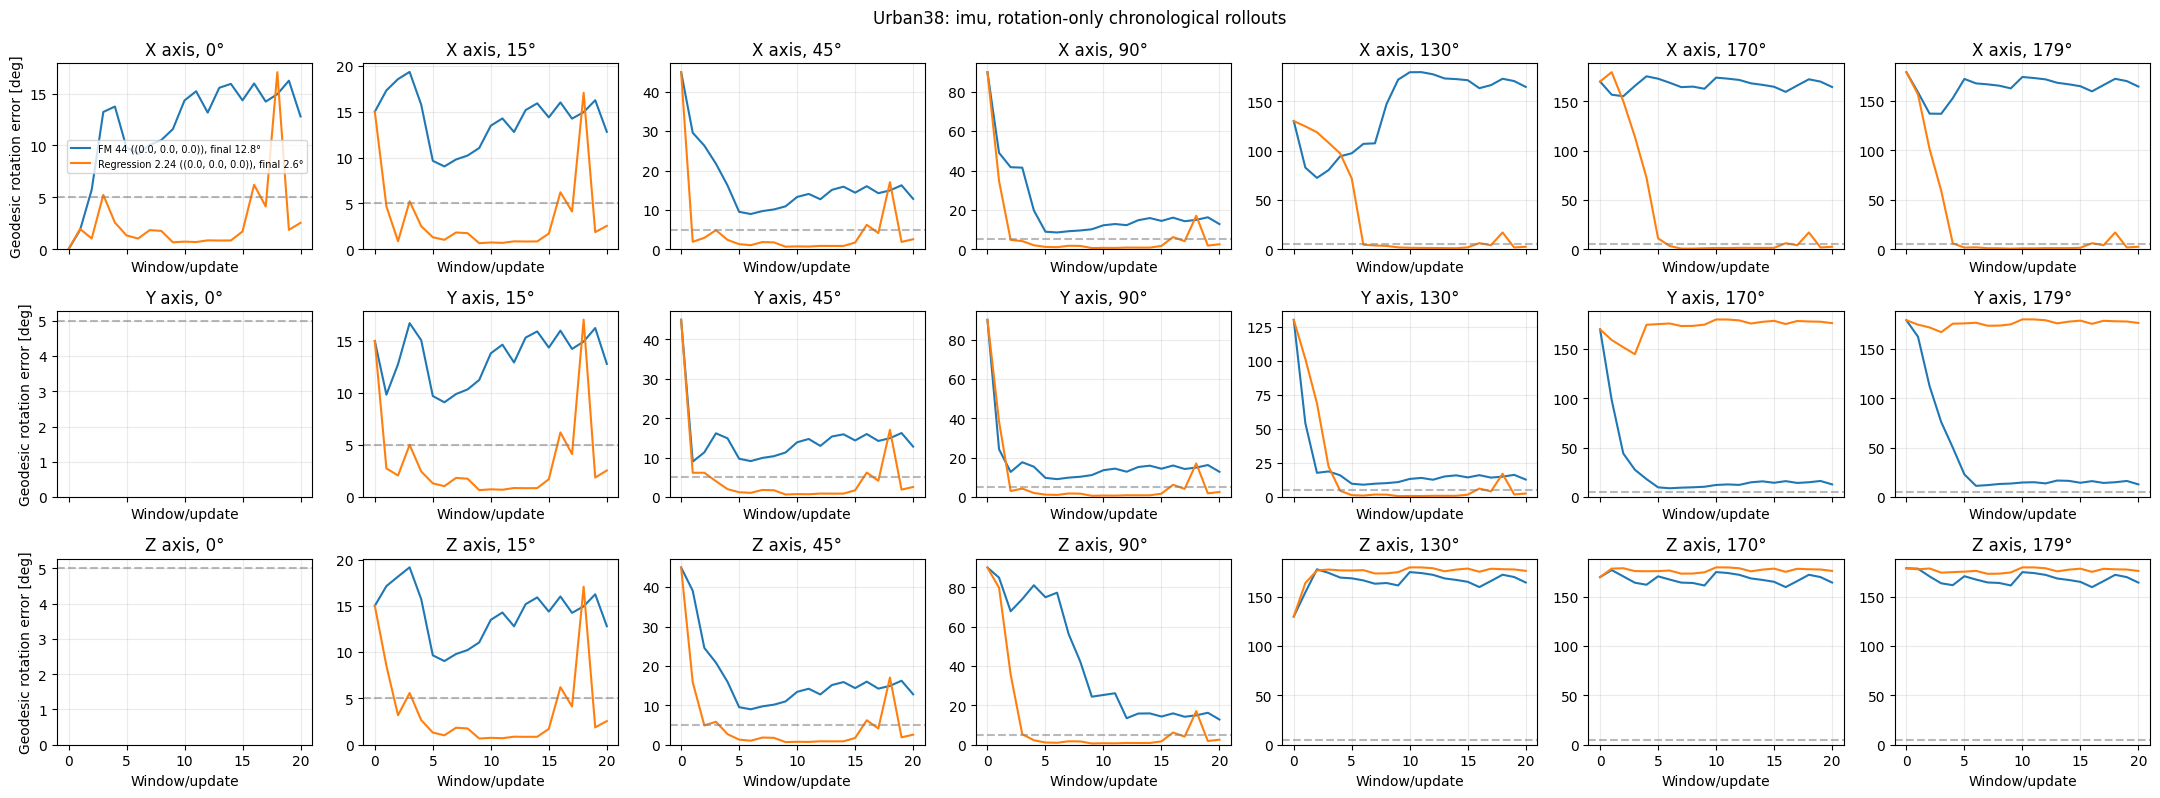

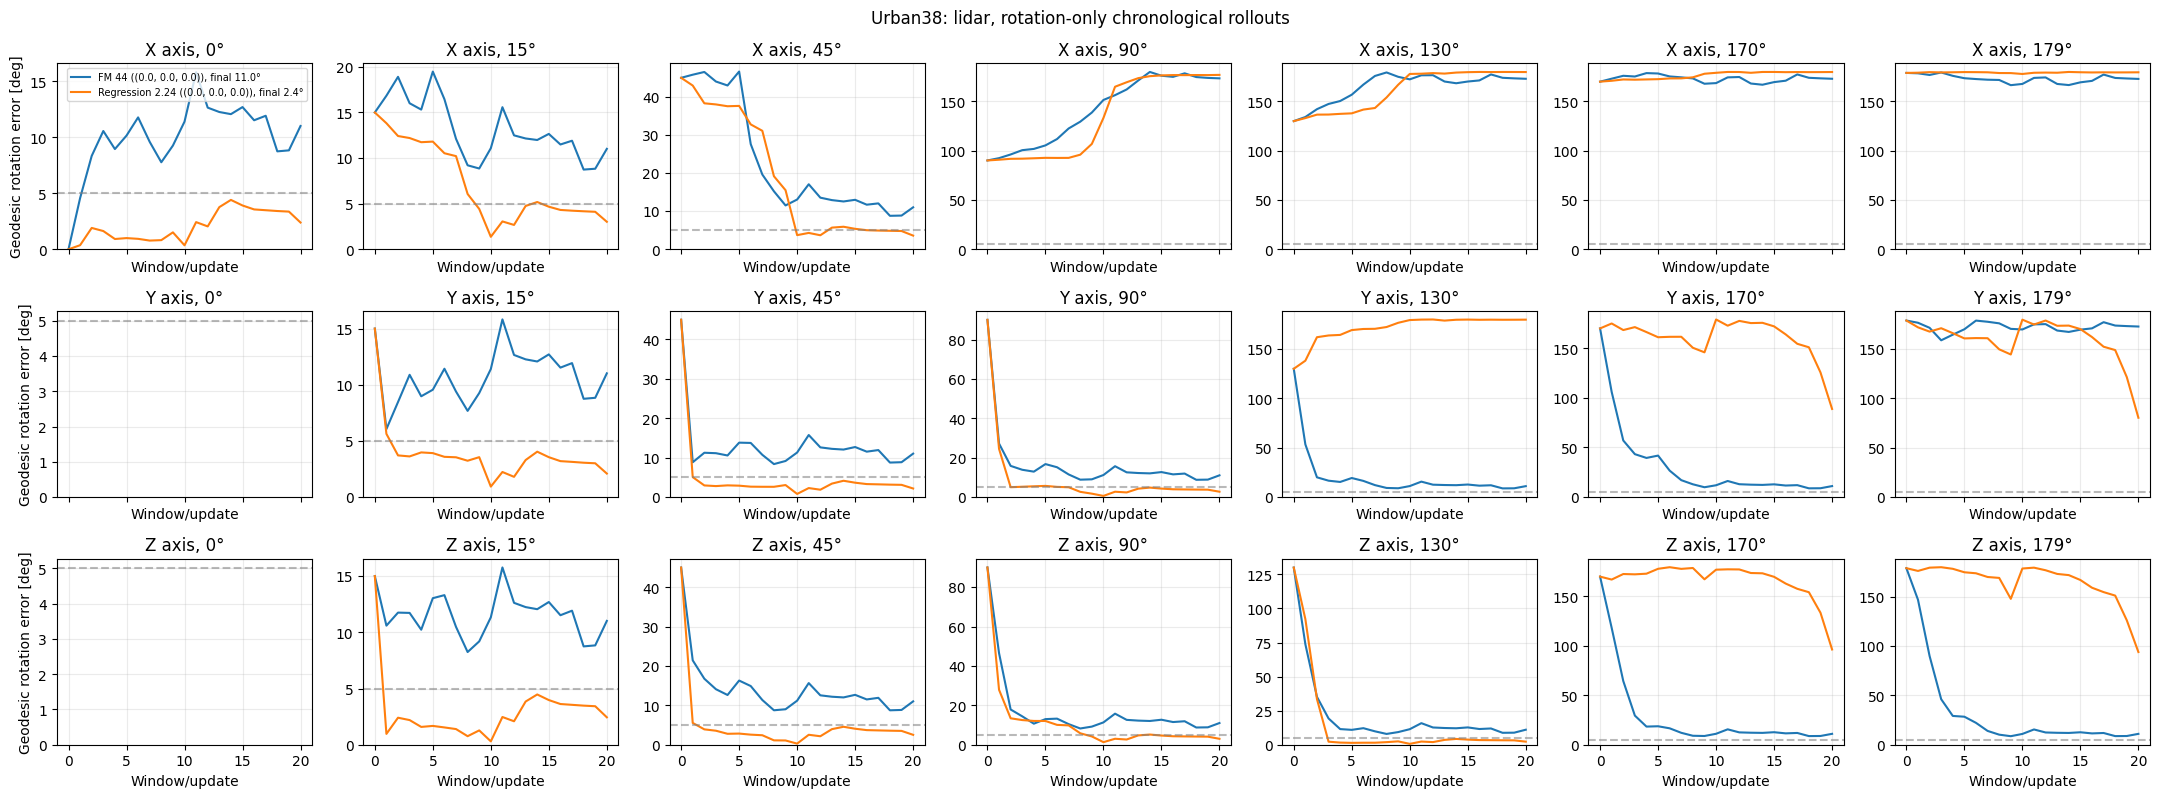

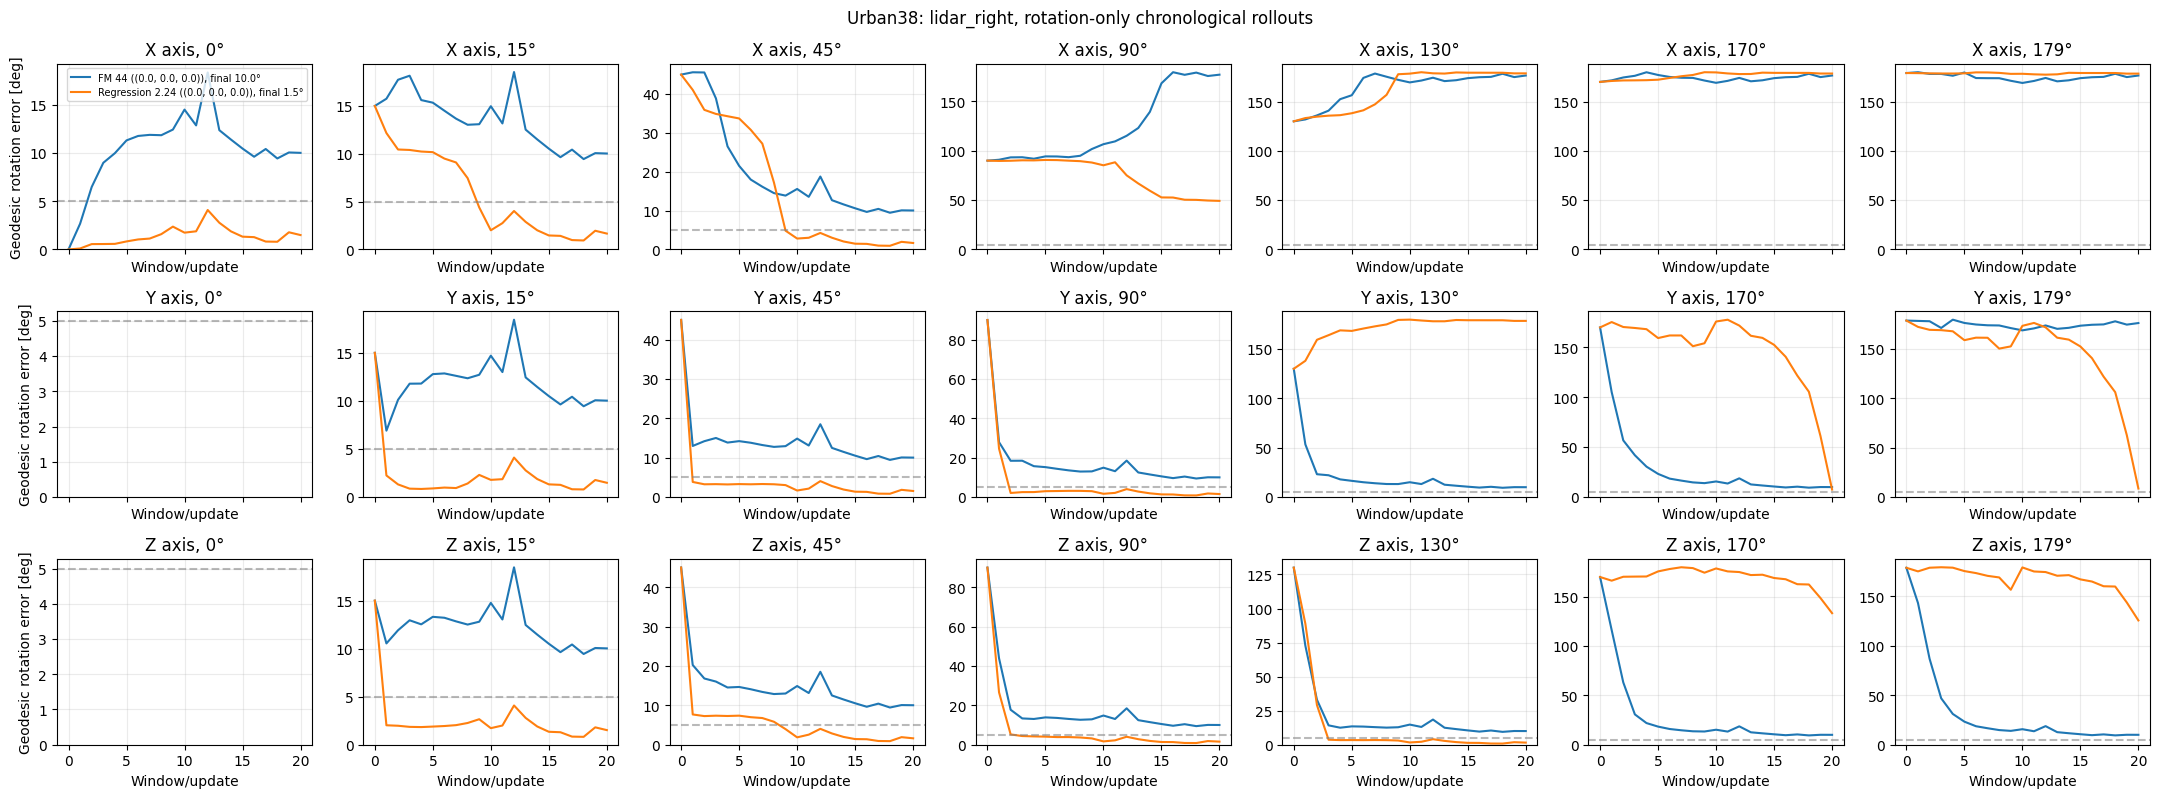

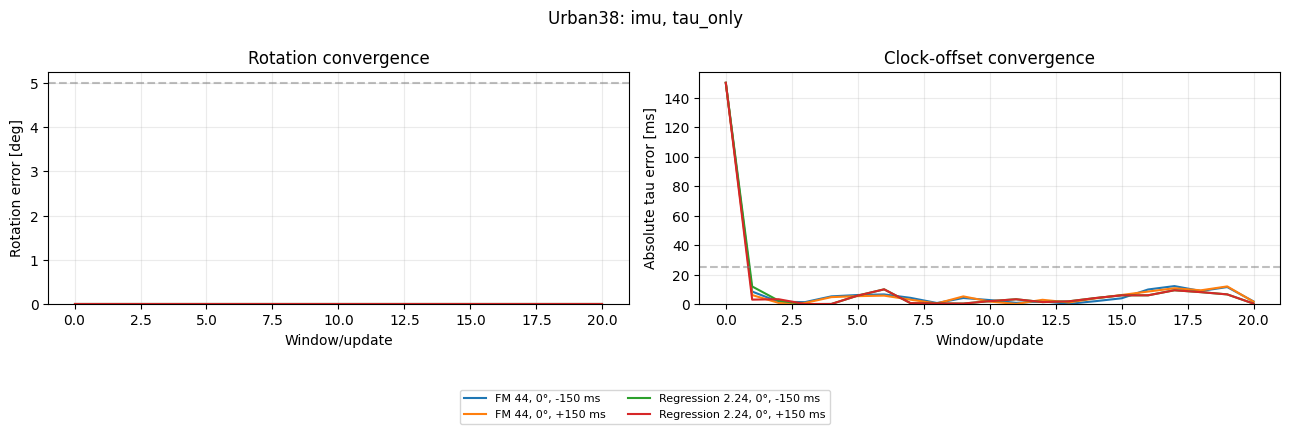

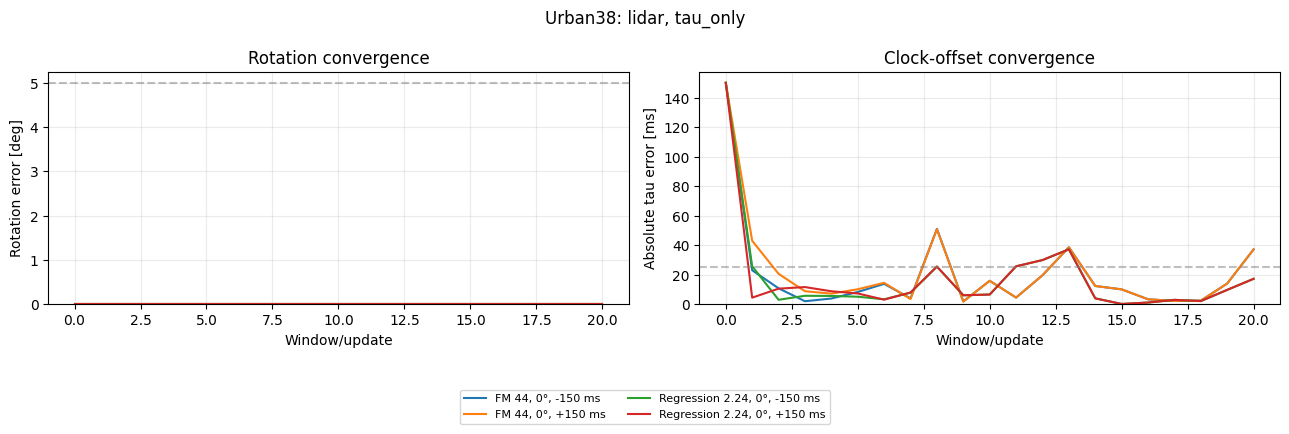

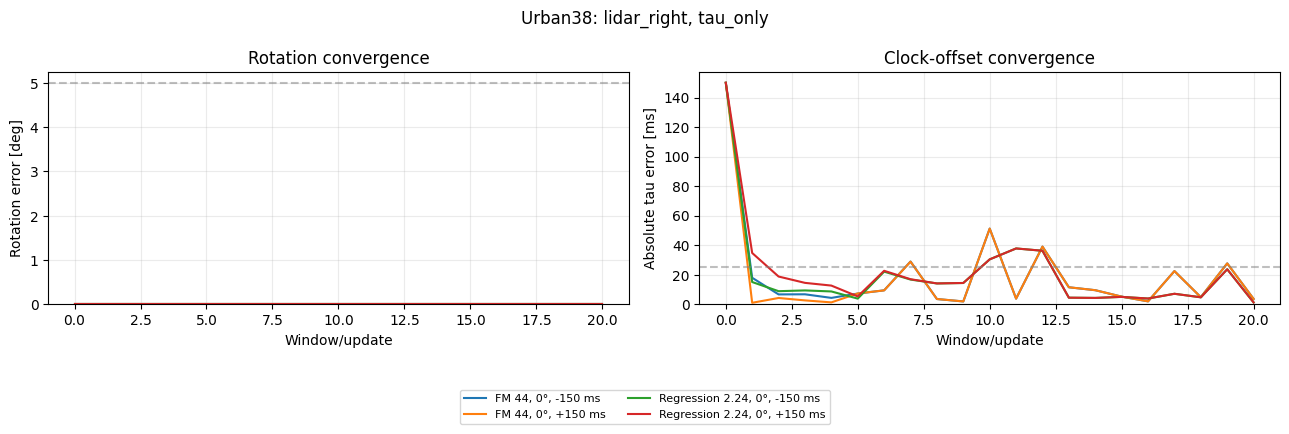

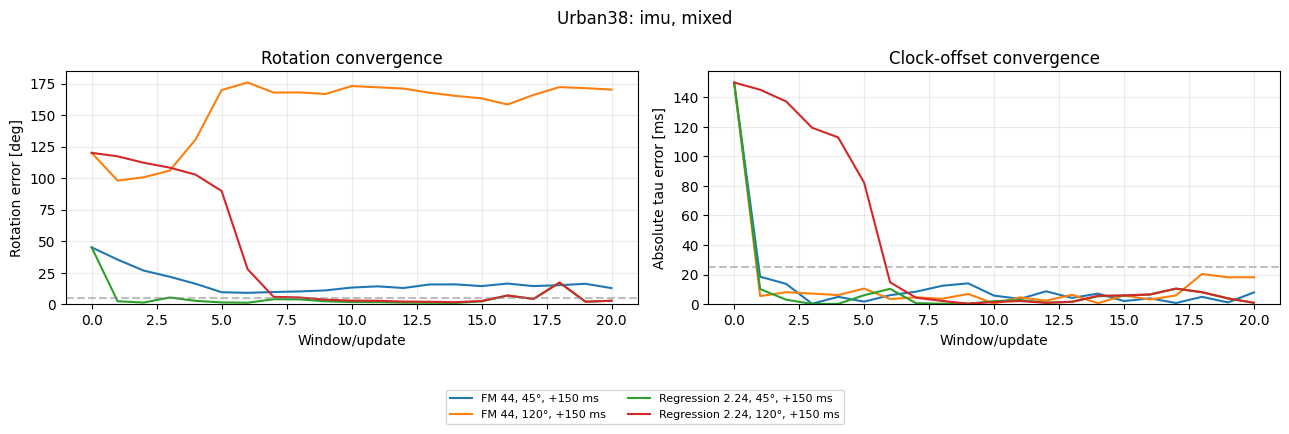

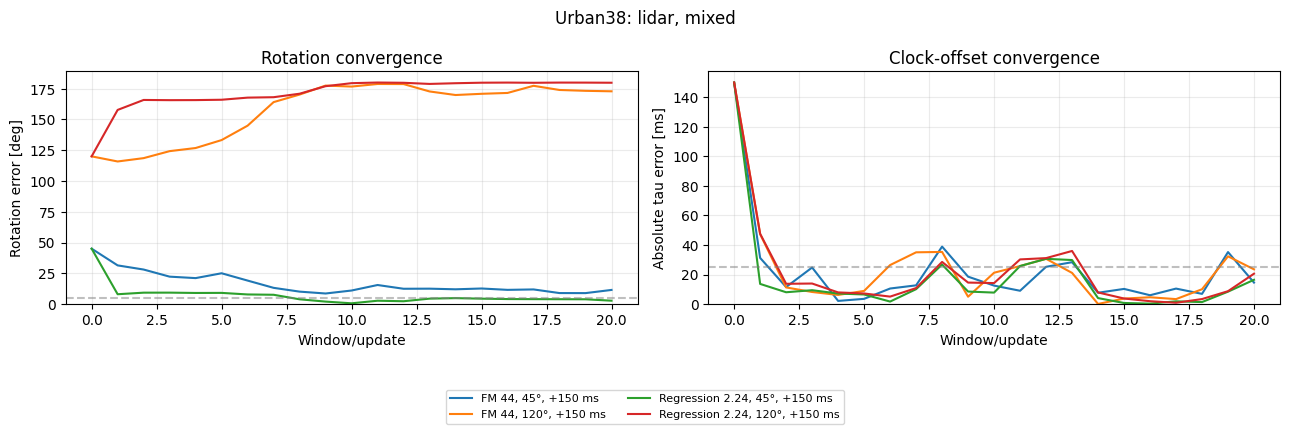

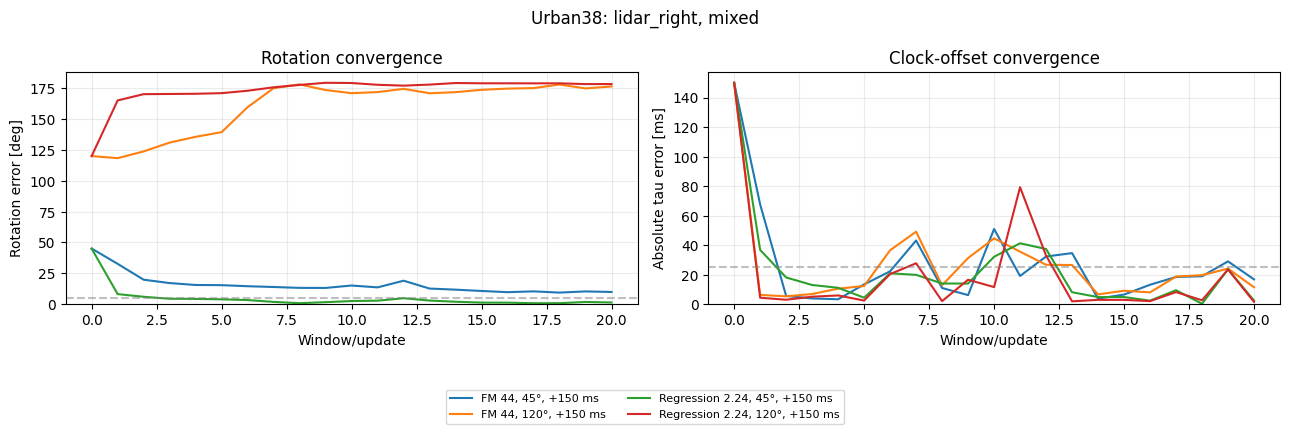

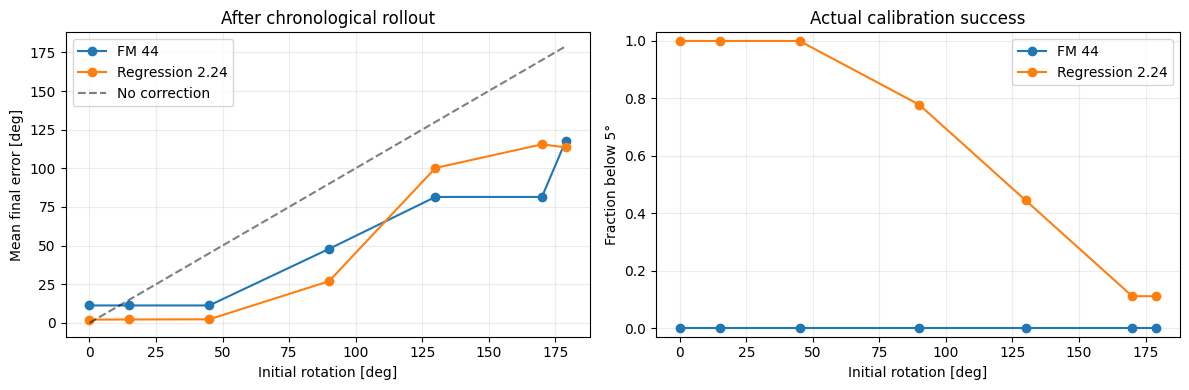

In [28]:
# Appendix 44.D: notebook 32-style sensor × axis × initial-angle convergence plots.
rotation_data = rollout_data[rollout_data.scenario == "rotation_only"]
if not rotation_data.empty:
    for sensor in ROLLOUT_SENSORS:
        angles = sorted(rotation_data.initial_angle_deg.unique())
        axes_names = sorted(rotation_data.axis.unique())
        fig, panels = plt.subplots(len(axes_names), len(angles), figsize=(3.1 * len(angles), 2.7 * len(axes_names)), sharex=True, squeeze=False)
        for i, axis in enumerate(axes_names):
            for j, angle in enumerate(angles):
                ax = panels[i, j]
                subset = rotation_data[(rotation_data.sensor == sensor) & (rotation_data.axis == axis) & np.isclose(rotation_data.initial_angle_deg, angle)]
                for (model_name, signed_vec), group in subset.groupby(["model", "signed_initial_rotvec_deg"]):
                    group = group.sort_values("step")
                    ax.plot(group.step, group.rotation_error_deg, label=f"{model_name} ({signed_vec}), final {group.rotation_error_deg.iloc[-1]:.1f}°", lw=1.5)
                ax.axhline(5.0, color="gray", ls="--", alpha=.55)
                ax.set(title=f"{axis.upper()} axis, {angle:g}°", xlabel="Window/update", ylim=(0, None))
                ax.grid(alpha=.25)
                if j == 0:
                    ax.set_ylabel("Geodesic rotation error [deg]")
                if i == 0 and j == 0:
                    ax.legend(fontsize=7)
        fig.suptitle(f"{ROLLOUT_SEQUENCE}: {sensor}, rotation-only chronological rollouts")
        fig.tight_layout()
        if ROLLOUT_SAVE_RESULTS:
            fig.savefig(ROLLOUT_DIR / f"rotation_rollouts_{sensor}.png", dpi=150, bbox_inches="tight")
        plt.show()

for scenario in ("tau_only", "mixed"):
    subset = rollout_data[rollout_data.scenario == scenario]
    if subset.empty:
        continue
    for sensor in ROLLOUT_SENSORS:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
        rows = subset[subset.sensor == sensor]
        for (model_name, initial_angle, initial_tau), group in rows.groupby(["model", "initial_angle_deg", "initial_tau_ms"]):
            group = group.sort_values("step")
            label = f"{model_name}, {initial_angle:g}°, {initial_tau:+g} ms"
            axes[0].plot(group.step, group.rotation_error_deg, label=label)
            axes[1].plot(group.step, group.tau_error_ms, label=label)
        axes[0].axhline(5.0, ls="--", color="gray", alpha=.5)
        axes[1].axhline(25.0, ls="--", color="gray", alpha=.5)
        axes[0].set(title="Rotation convergence", ylabel="Rotation error [deg]")
        axes[1].set(title="Clock-offset convergence", ylabel="Absolute tau error [ms]")
        for ax in axes:
            ax.set(xlabel="Window/update", ylim=(0, None))
            ax.grid(alpha=.25)
        handles, labels = axes[1].get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(.5, -.02), fontsize=8, ncol=2)
        fig.suptitle(f"{ROLLOUT_SEQUENCE}: {sensor}, {scenario}")
        fig.tight_layout(rect=(0, .14, 1, 1))
        if ROLLOUT_SAVE_RESULTS:
            fig.savefig(ROLLOUT_DIR / f"{scenario}_rollouts_{sensor}.png", dpi=150, bbox_inches="tight")
        plt.show()

# A compact final-angle comparison. Unlike a binary 'improved' indicator, this shows
# whether the rollout actually reaches a useful calibration threshold.
if not rotation_data.empty:
    final_rotation = rollout_terminal[rollout_terminal.scenario == "rotation_only"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for model_name, group in final_rotation.groupby("model"):
        means = group.groupby("initial_angle_deg")["rotation_error_deg"].mean()
        solved = group.groupby("initial_angle_deg")["solved_5deg"].mean()
        axes[0].plot(means.index, means, "-o", label=model_name)
        axes[1].plot(solved.index, solved, "-o", label=model_name)
    axes[0].plot(sorted(final_rotation.initial_angle_deg.unique()), sorted(final_rotation.initial_angle_deg.unique()), "k--", alpha=.5, label="No correction")
    axes[0].set(xlabel="Initial rotation [deg]", ylabel="Mean final error [deg]", title="After chronological rollout")
    axes[1].set(xlabel="Initial rotation [deg]", ylabel="Fraction below 5°", ylim=(-.03, 1.03), title="Actual calibration success")
    for ax in axes:
        ax.grid(alpha=.25)
        ax.legend()
    fig.tight_layout()
    if ROLLOUT_SAVE_RESULTS:
        fig.savefig(ROLLOUT_DIR / "rollout_final_angle_summary.png", dpi=150, bbox_inches="tight")
    plt.show()

if DEVICE.type == "cuda": torch.cuda.empty_cache()